# 05 — Avaliação das Previsões e Melhores Períodos de Compra

## Objetivo

Avaliar o desempenho dos modelos de previsão de preços dos
alimentos da cesta básica, utilizando métricas de erro e
comparações entre valores reais e previstos.

A análise também busca identificar os períodos mais favoráveis
para a compra de cada produto, considerando o histórico de
preços, a sazonalidade e as previsões futuras.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures" / "avaliacao"

FIGURES.mkdir(parents=True, exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.avaliacao import (
    MODELOS, calcular_metricas, selecionar_melhores_modelos,
    comparar_baseline, gerar_ranking, classificar_evidencia
)


In [2]:
teste_1passo = pd.read_csv(
    DATA / "previsoes_teste_1passo.csv",
    parse_dates=["mes"]
)

teste_multipassos = pd.read_csv(
    DATA / "previsoes_teste_multipassos.csv",
    parse_dates=["mes"]
)

previsoes_futuras = pd.read_csv(
    DATA / "previsoes_futuras.csv",
    parse_dates=["mes"]
)

historico = pd.read_csv(
    DATA / "cesta_mensal.csv",
    parse_dates=["mes"]
)

sazonalidade = pd.read_csv(
    REPORTS / "sazonalidade" / "perfis_mensais.csv"
)

testes_sazonais = pd.read_csv(
    REPORTS / "sazonalidade" / "testes_sazonalidade.csv",
    usecols=["produto", "q_bh", "evidencia_principal"]
)

print("Bases carregadas com sucesso!")

Bases carregadas com sucesso!


In [3]:
bases = {
    "Teste de um passo": teste_1passo,
    "Teste de múltiplos passos": teste_multipassos,
    "Previsões futuras": previsoes_futuras,
    "Histórico mensal": historico,
    "Sazonalidade": sazonalidade
}

for nome, df in bases.items():
    print(f"\n{nome}")
    print(f"Registros: {len(df)}")
    print(f"Produtos: {df['produto'].nunique()}")
    print(f"Valores ausentes: {df.isna().sum().sum()}")

    if "mes" in df.columns and pd.api.types.is_datetime64_any_dtype(df["mes"]):
        print(f"Início: {df['mes'].min():%m/%Y}")
        print(f"Fim: {df['mes'].max():%m/%Y}")


Teste de um passo
Registros: 168
Produtos: 14
Valores ausentes: 0
Início: 09/2025
Fim: 08/2026

Teste de múltiplos passos
Registros: 168
Produtos: 14
Valores ausentes: 0
Início: 09/2025
Fim: 08/2026

Previsões futuras
Registros: 84
Produtos: 14
Valores ausentes: 0
Início: 09/2026
Fim: 02/2027

Histórico mensal
Registros: 780
Produtos: 20
Valores ausentes: 0
Início: 09/2022
Fim: 08/2026

Sazonalidade
Registros: 168
Produtos: 14
Valores ausentes: 0


## 2. Avaliação dos modelos de previsão

Nesta etapa, os modelos Baseline, Ridge Regression,
Random Forest e Holt-Winters serão avaliados por meio
das métricas MAE e RMSE.

A avaliação será realizada individualmente para cada
produto, considerando os cenários de previsão de um
passo e de múltiplos passos.

In [4]:
modelos = MODELOS.copy()


In [5]:
metricas_1passo = calcular_metricas(
    teste_1passo,
    "Um passo"
)

metricas_multipassos = calcular_metricas(
    teste_multipassos,
    "Múltiplos passos"
)

metricas = pd.concat(
    [metricas_1passo, metricas_multipassos],
    ignore_index=True
)

display(metricas.round(4))

,produto,modelo,cenario,n_observacoes,MAE,RMSE
0,Arroz,Baseline,Um passo,12,0.1867,0.2925
1,Arroz,Ridge Regression,Um passo,12,0.2159,0.3183
2,Arroz,Random Forest,Um passo,12,0.2292,0.3013
3,Arroz,Holt-Winters,Um passo,12,0.1827,0.2722
4,Açúcar,Baseline,Um passo,12,0.1167,0.1708
...,...,...,...,...,...,...
107,Tomate,Holt-Winters,Múltiplos passos,12,3.3746,3.7106
108,Óleo,Baseline,Múltiplos passos,12,0.5130,0.6423
109,Óleo,Ridge Regression,Múltiplos passos,12,0.4817,0.5451
110,Óleo,Random Forest,Múltiplos passos,12,0.3149,0.3861


In [6]:
metricas.to_csv(
    DATA / "metricas_modelos.csv",
    index=False
)

print("Métricas calculadas e salvas com sucesso!")
print(f"Total de avaliações: {len(metricas)}")
print(f"Produtos avaliados: {metricas['produto'].nunique()}")

Métricas calculadas e salvas com sucesso!
Total de avaliações: 112
Produtos avaliados: 14


## 3. Comparação do desempenho dos modelos

Nesta etapa, os modelos serão classificados de acordo
com os erros obtidos para cada produto.

O MAE será utilizado como principal critério de seleção,
enquanto o RMSE será utilizado como critério complementar.

Também será analisado se os modelos apresentam desempenho
superior ao Baseline, utilizado como referência.

In [7]:
melhores_modelos = selecionar_melhores_modelos(metricas)
display(melhores_modelos.round(4))


,produto,modelo,cenario,n_observacoes,MAE,RMSE
0,Arroz,Holt-Winters,Múltiplos passos,12,0.5936,0.6448
1,Arroz,Holt-Winters,Um passo,12,0.1827,0.2722
2,Açúcar,Random Forest,Múltiplos passos,12,0.2980,0.4127
3,Açúcar,Baseline,Um passo,12,0.1167,0.1708
4,Banana Nanica,Baseline,Múltiplos passos,12,0.3958,0.5851
5,Banana Nanica,Ridge Regression,Um passo,12,0.4470,0.5417
6,Banana Prata,Ridge Regression,Múltiplos passos,12,0.7295,0.8605
7,Banana Prata,Ridge Regression,Um passo,12,0.5817,0.8906
8,Batata,Ridge Regression,Múltiplos passos,12,1.3032,1.5602
9,Batata,Ridge Regression,Um passo,12,1.0579,1.3960


In [8]:
comparacao = comparar_baseline(metricas)
display(comparacao.round(4))


,produto,modelo,cenario,n_observacoes,MAE,RMSE,MAE_baseline,RMSE_baseline,melhoria_MAE_pct,superou_baseline
0,Arroz,Baseline,Um passo,12,0.1867,0.2925,0.1867,0.2925,0.0000,False
1,Arroz,Ridge Regression,Um passo,12,0.2159,0.3183,0.1867,0.2925,-15.6873,False
2,Arroz,Random Forest,Um passo,12,0.2292,0.3013,0.1867,0.2925,-22.7995,False
3,Arroz,Holt-Winters,Um passo,12,0.1827,0.2722,0.1867,0.2925,2.1485,True
4,Açúcar,Baseline,Um passo,12,0.1167,0.1708,0.1167,0.1708,0.0000,False
...,...,...,...,...,...,...,...,...,...,...
107,Tomate,Holt-Winters,Múltiplos passos,12,3.3746,3.7106,1.9842,2.2913,-70.0789,False
108,Óleo,Baseline,Múltiplos passos,12,0.5130,0.6423,0.5130,0.6423,0.0000,False
109,Óleo,Ridge Regression,Múltiplos passos,12,0.4817,0.5451,0.5130,0.6423,6.1011,True
110,Óleo,Random Forest,Múltiplos passos,12,0.3149,0.3861,0.5130,0.6423,38.6273,True


In [9]:
ranking_modelos = gerar_ranking(melhores_modelos)
display(ranking_modelos)


,cenario,modelo,produtos_vencedores
0,Múltiplos passos,Ridge Regression,7
1,Múltiplos passos,Holt-Winters,4
2,Múltiplos passos,Random Forest,2
3,Múltiplos passos,Baseline,1
4,Um passo,Baseline,6
5,Um passo,Ridge Regression,5
6,Um passo,Holt-Winters,2
7,Um passo,Random Forest,1


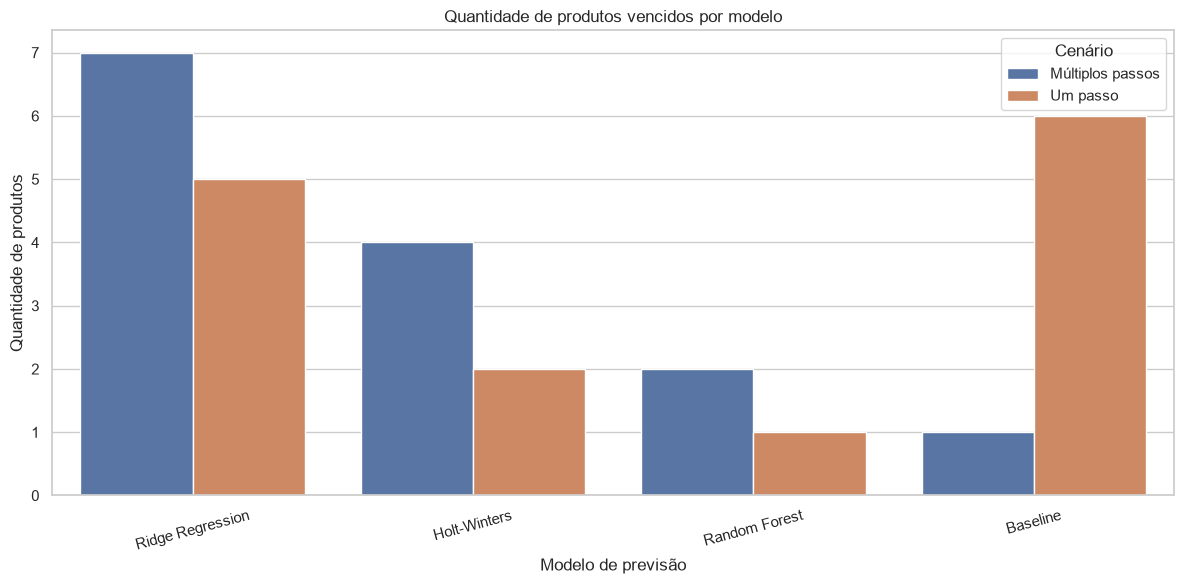

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=ranking_modelos,
    x="modelo",
    y="produtos_vencedores",
    hue="cenario"
)

plt.title("Quantidade de produtos vencidos por modelo")
plt.xlabel("Modelo de previsão")
plt.ylabel("Quantidade de produtos")
plt.xticks(rotation=15)
plt.legend(title="Cenário")
plt.tight_layout()

plt.savefig(
    FIGURES / "ranking_modelos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
melhores_modelos.to_csv(
    DATA / "melhores_modelos.csv",
    index=False
)

comparacao.to_csv(
    DATA / "comparacao_baseline.csv",
    index=False
)

ranking_modelos.to_csv(
    DATA / "ranking_modelos.csv",
    index=False
)

print("Comparações salvas com sucesso!")

Comparações salvas com sucesso!


## 4. Visualização do desempenho dos modelos

Serão apresentados gráficos comparativos das métricas
MAE e RMSE para cada produto e modelo de previsão.

Também serão comparados os valores reais e previstos
ao longo do período de teste, permitindo identificar
a capacidade dos modelos de acompanhar as variações
dos preços.

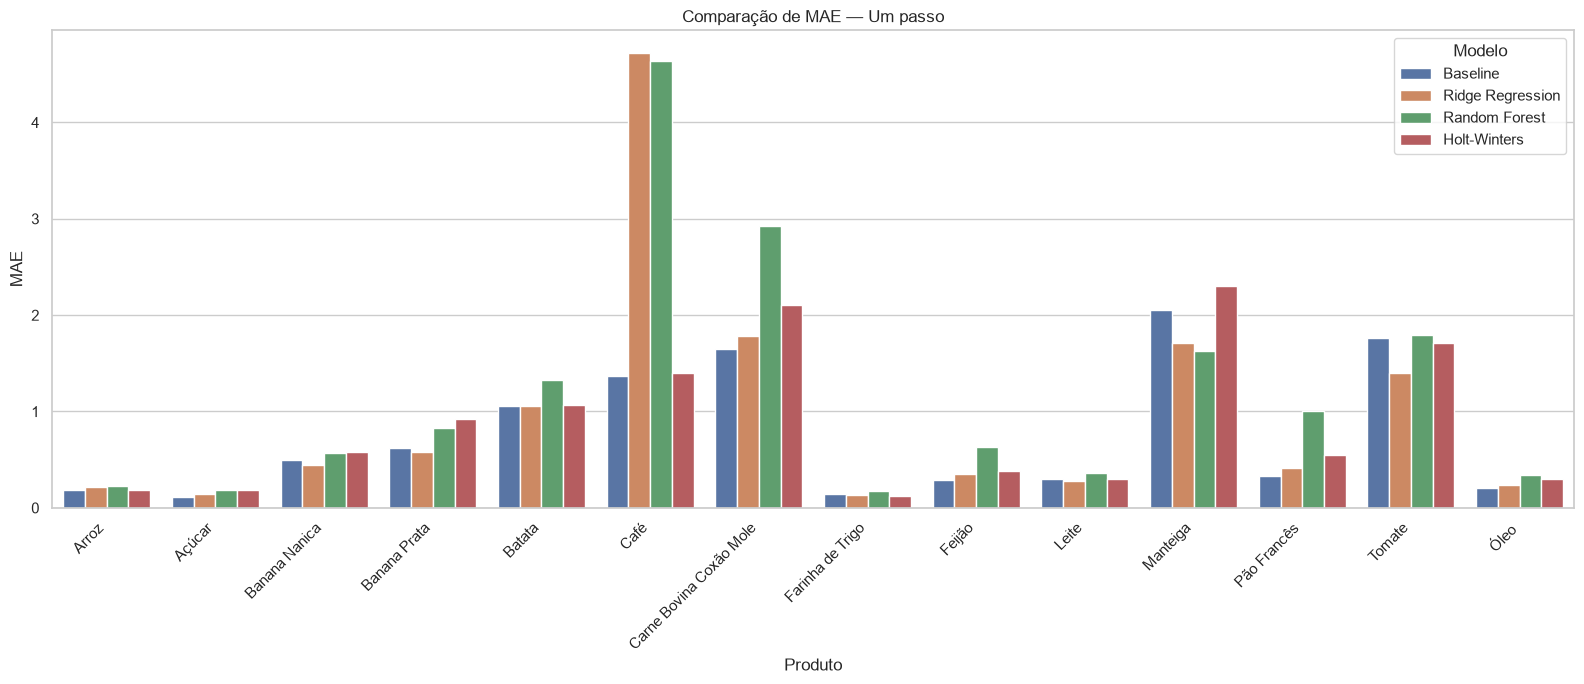

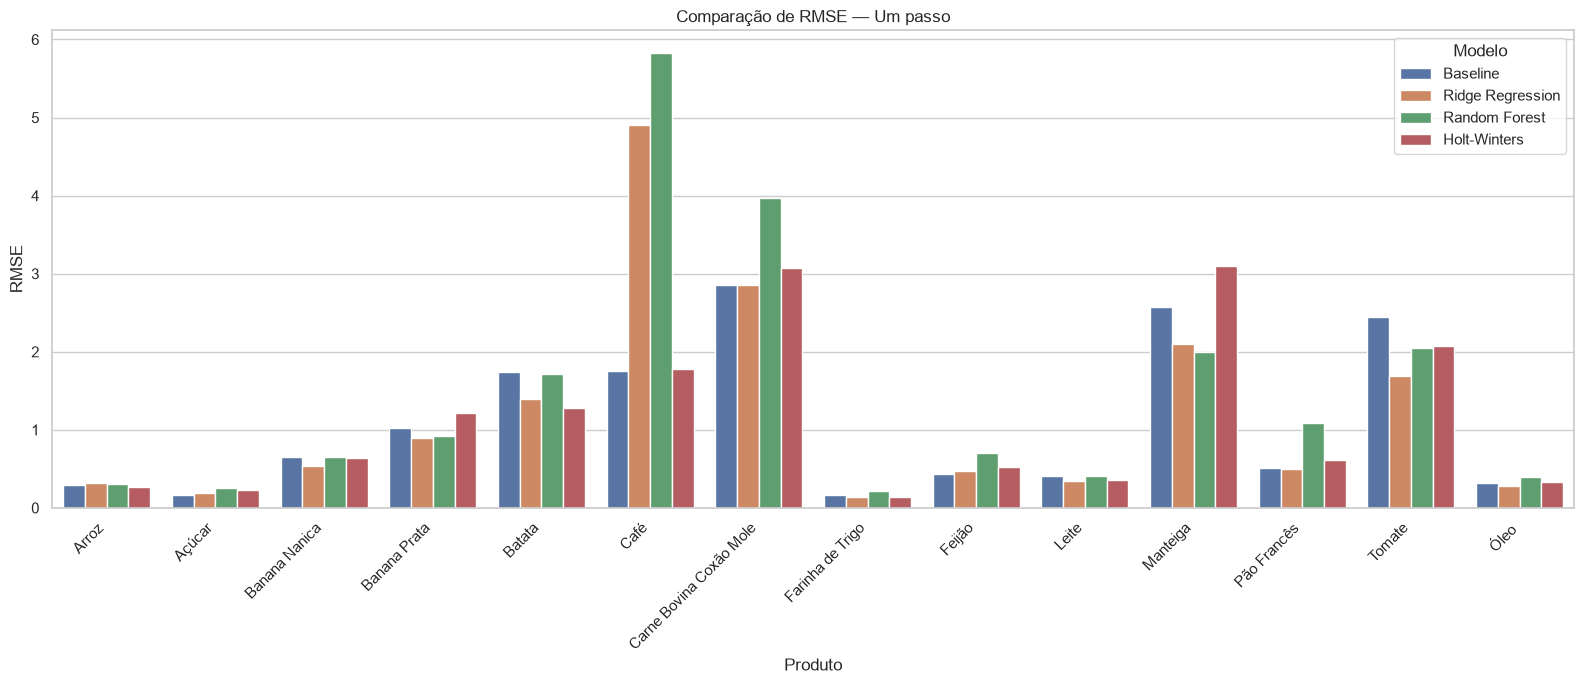

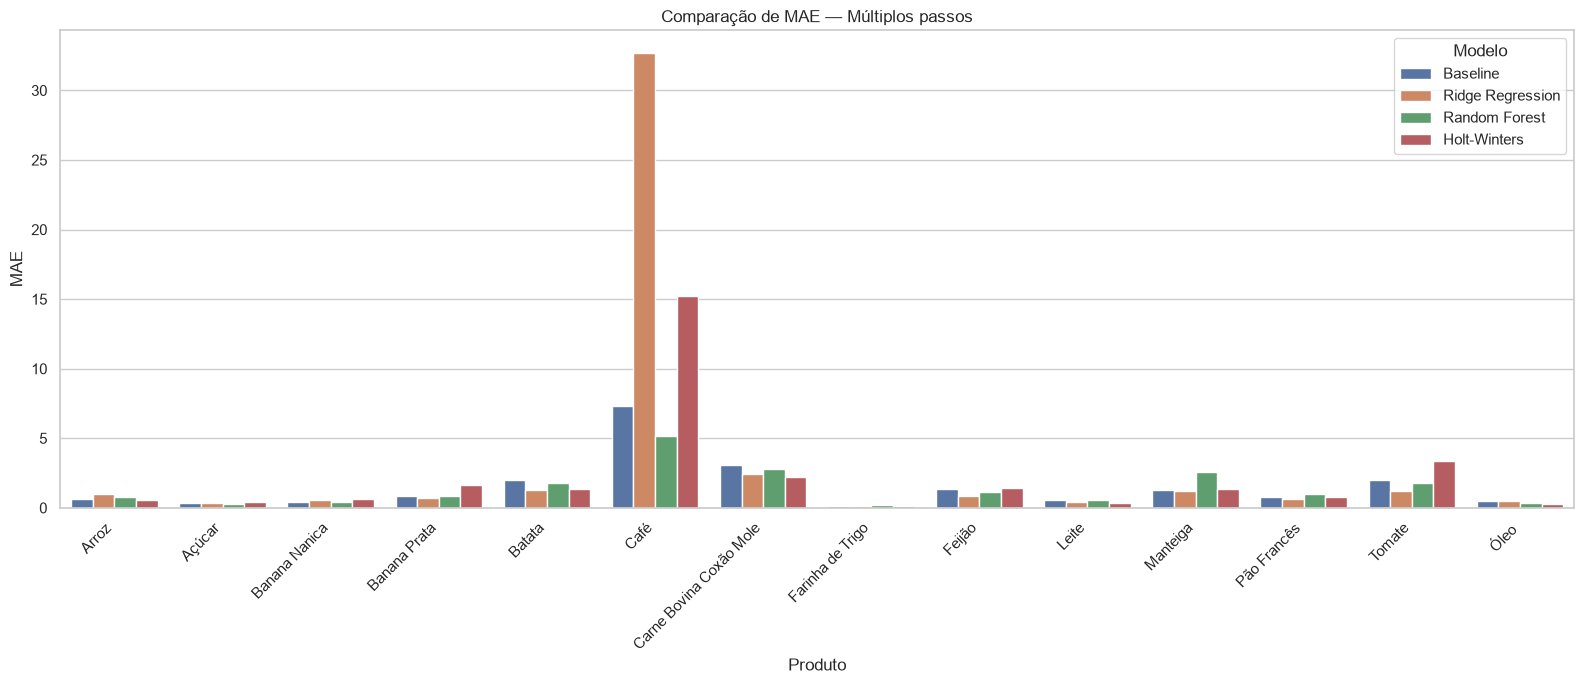

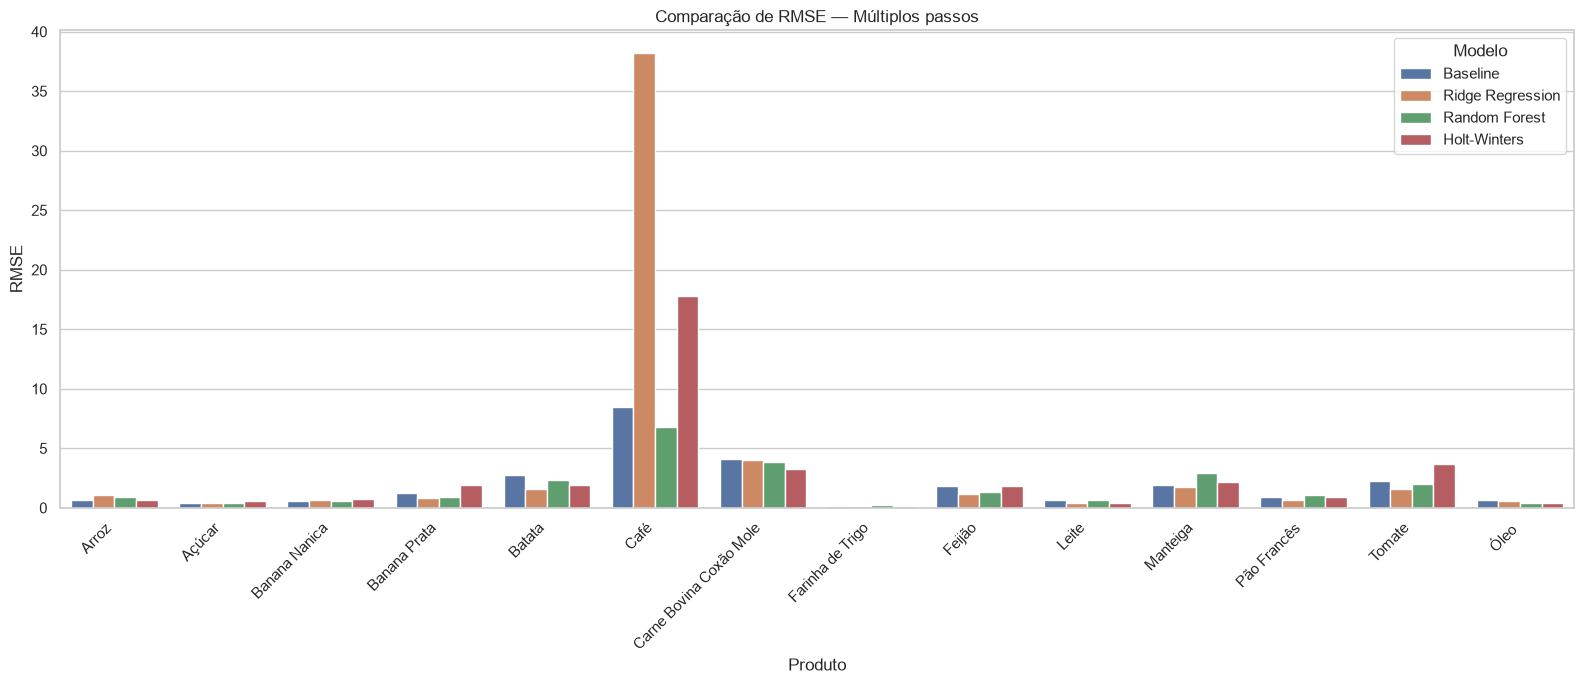

In [12]:
for cenario in metricas["cenario"].unique():

    dados = metricas[metricas["cenario"] == cenario]

    for metrica in ["MAE", "RMSE"]:

        plt.figure(figsize=(16, 7))

        sns.barplot(
            data=dados,
            x="produto",
            y=metrica,
            hue="modelo"
        )

        plt.title(f"Comparação de {metrica} — {cenario}")
        plt.xlabel("Produto")
        plt.ylabel(metrica)
        plt.xticks(rotation=45, ha="right")
        plt.legend(title="Modelo")
        plt.tight_layout()

        nome = (
            "1passo"
            if cenario == "Um passo"
            else "multipassos"
        )

        plt.savefig(
            FIGURES / f"comparacao_{metrica.lower()}_{nome}.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

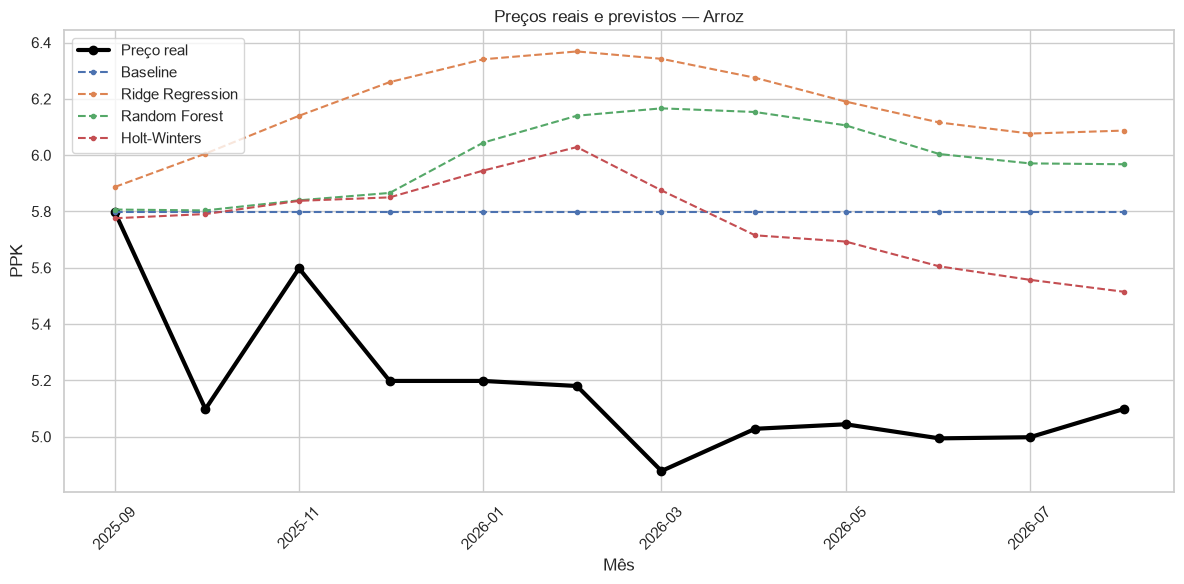

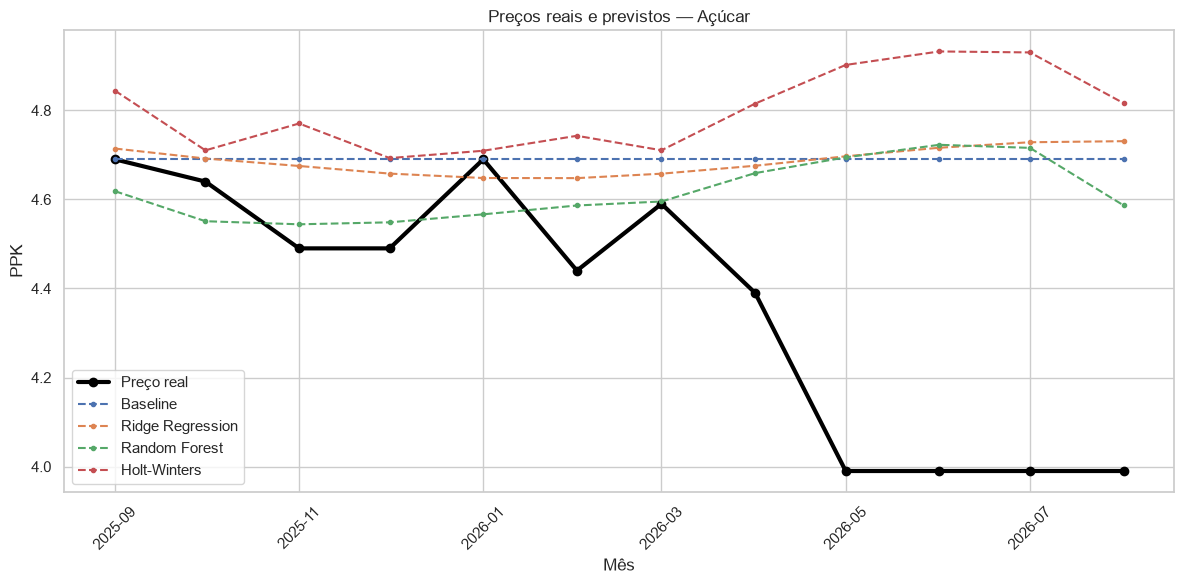

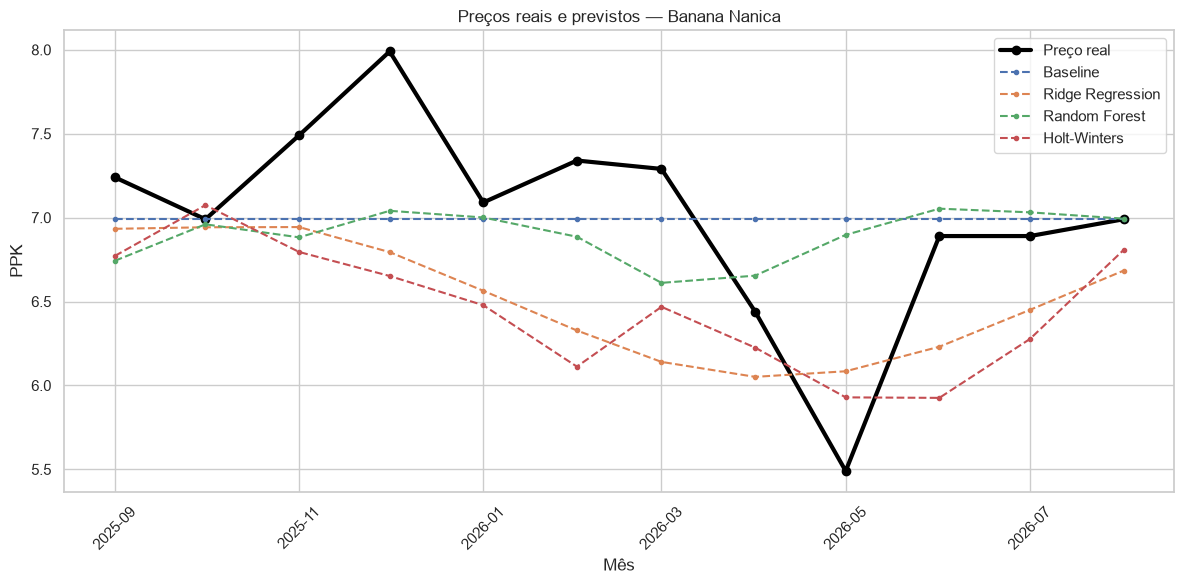

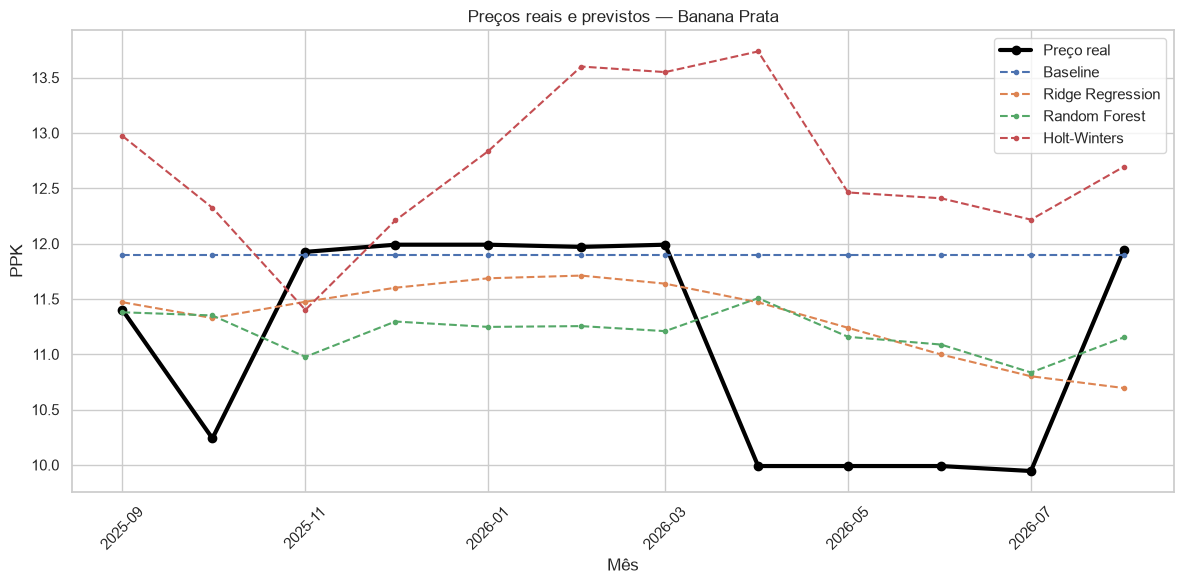

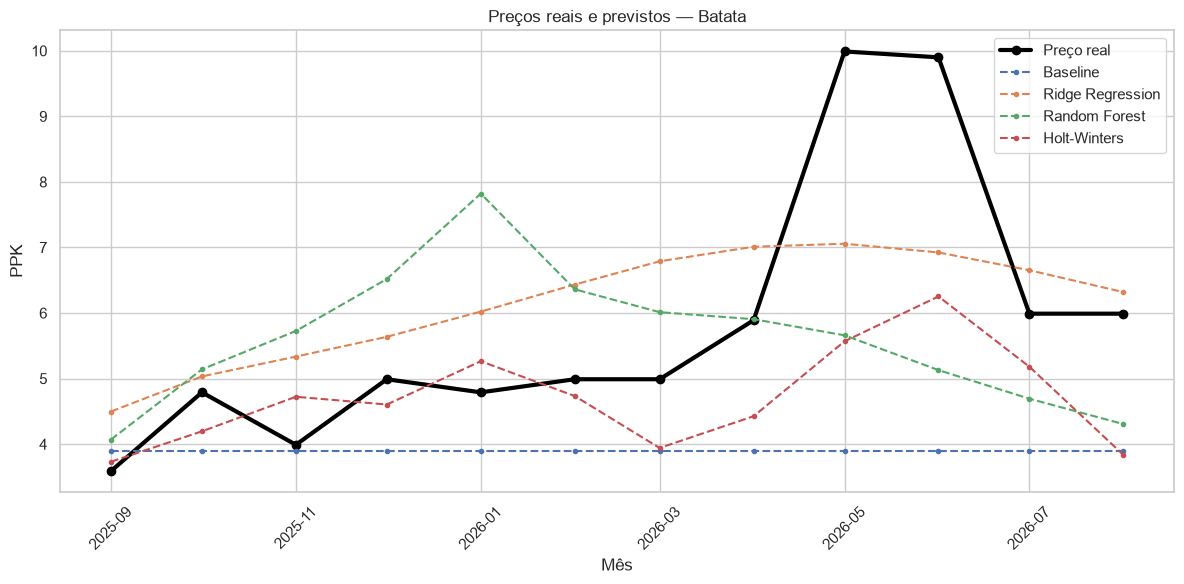

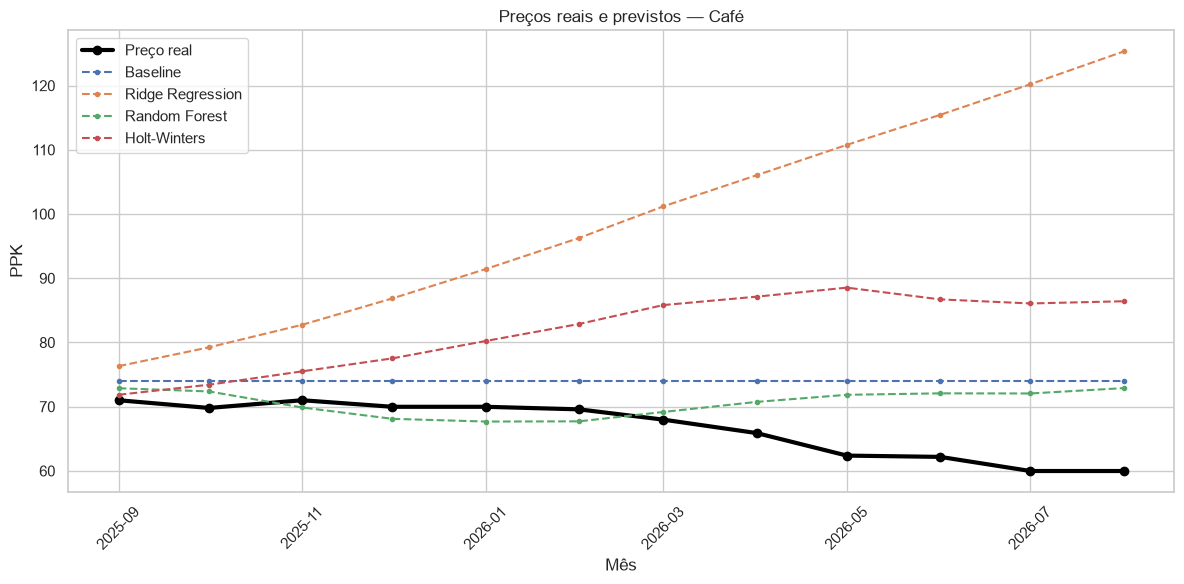

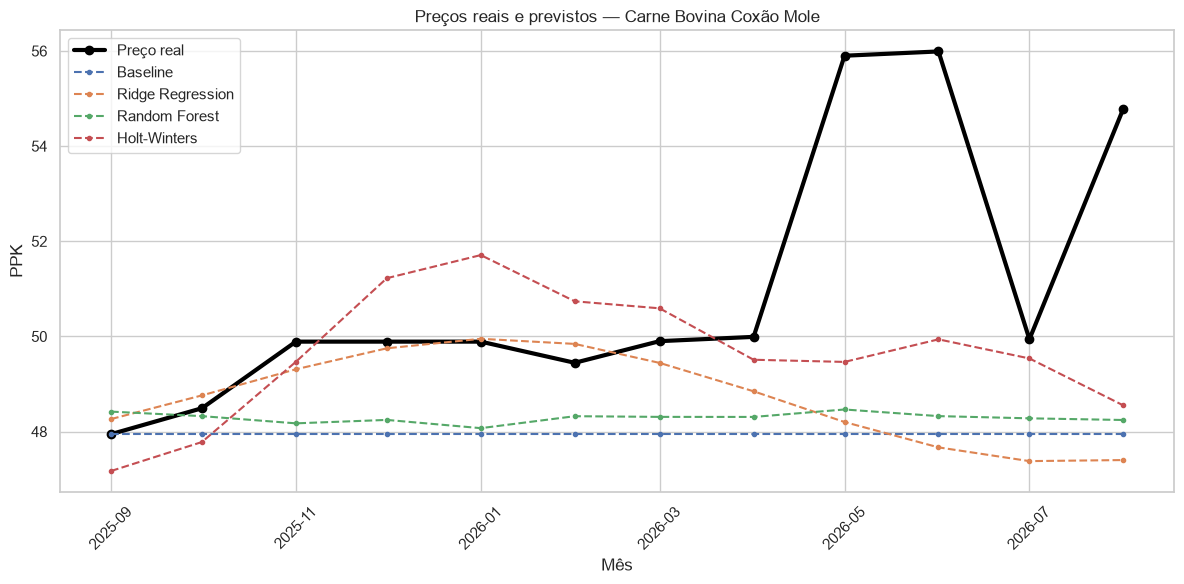

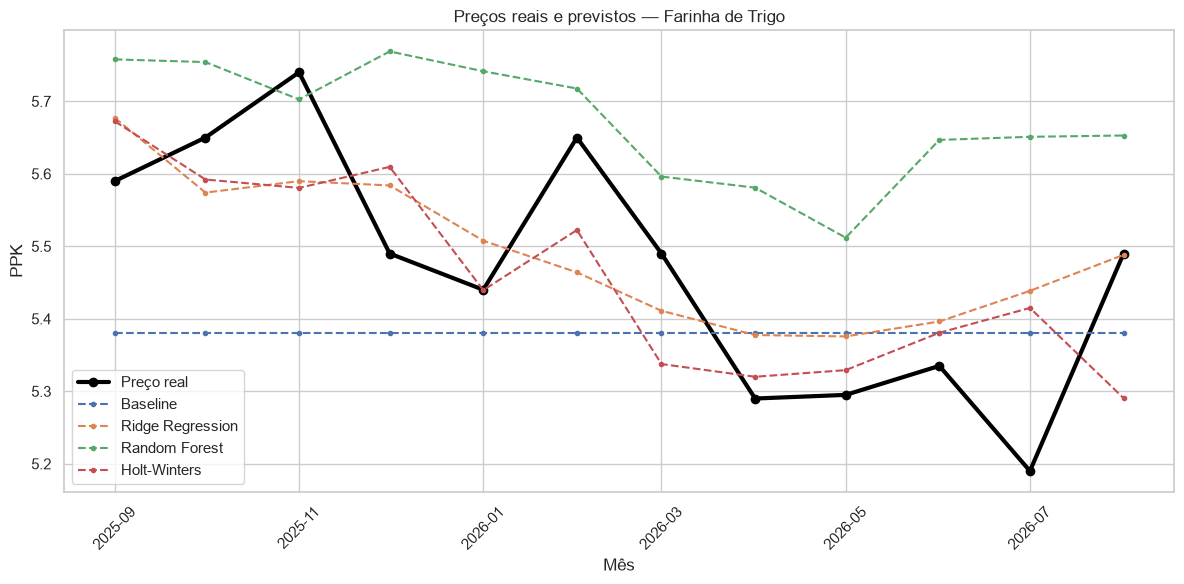

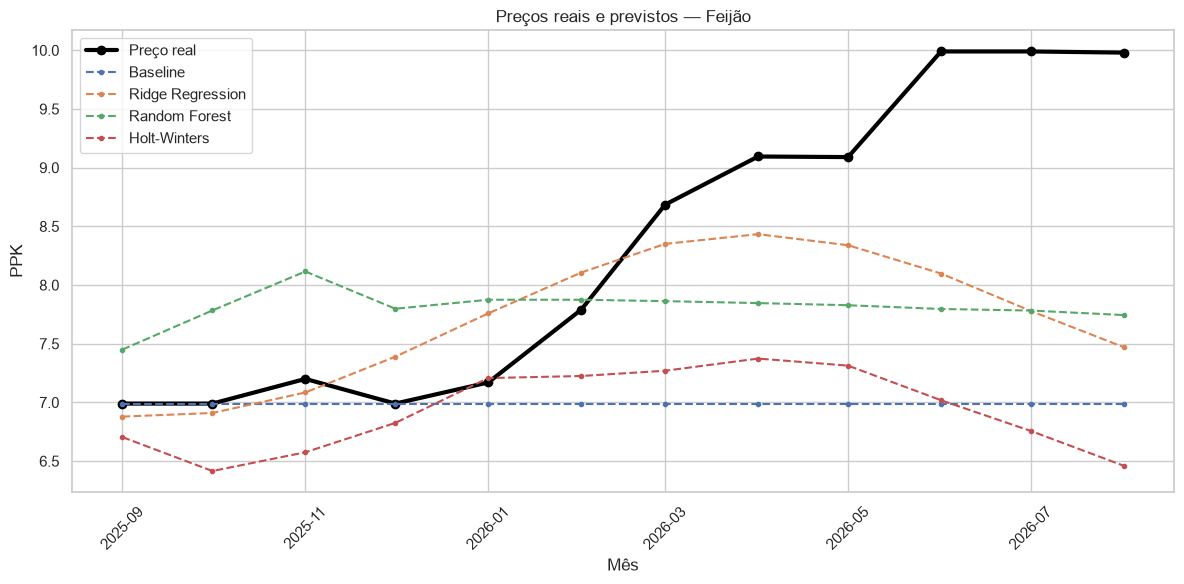

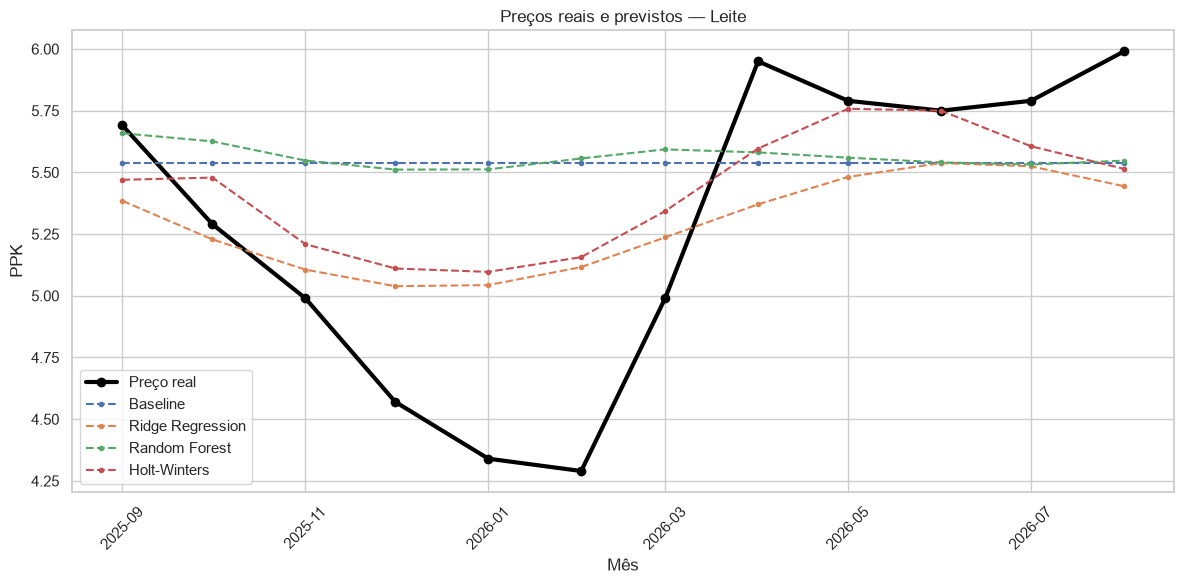

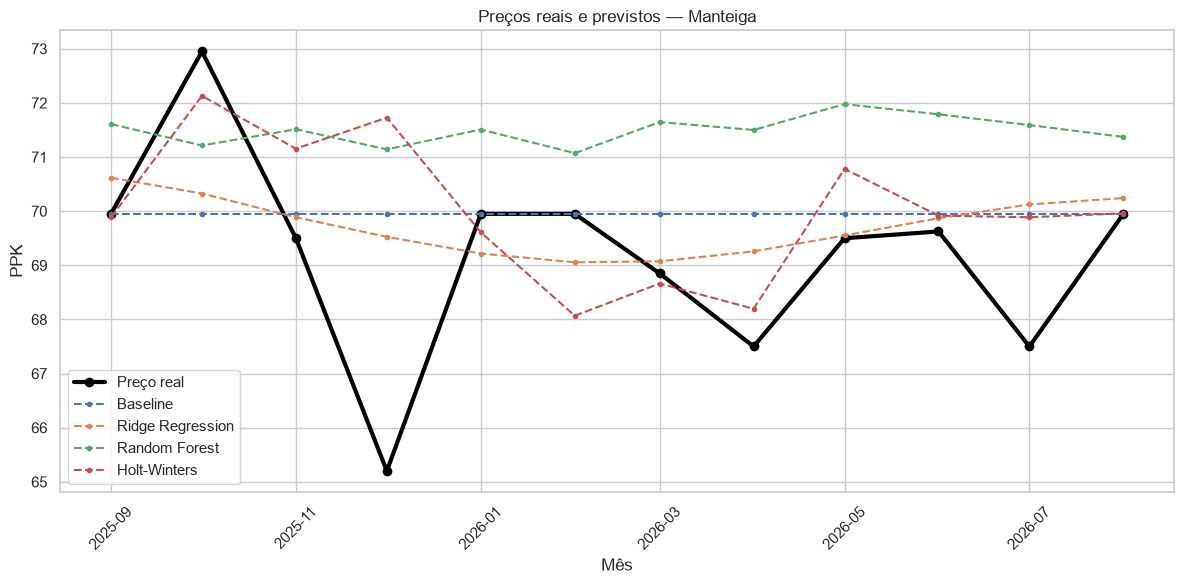

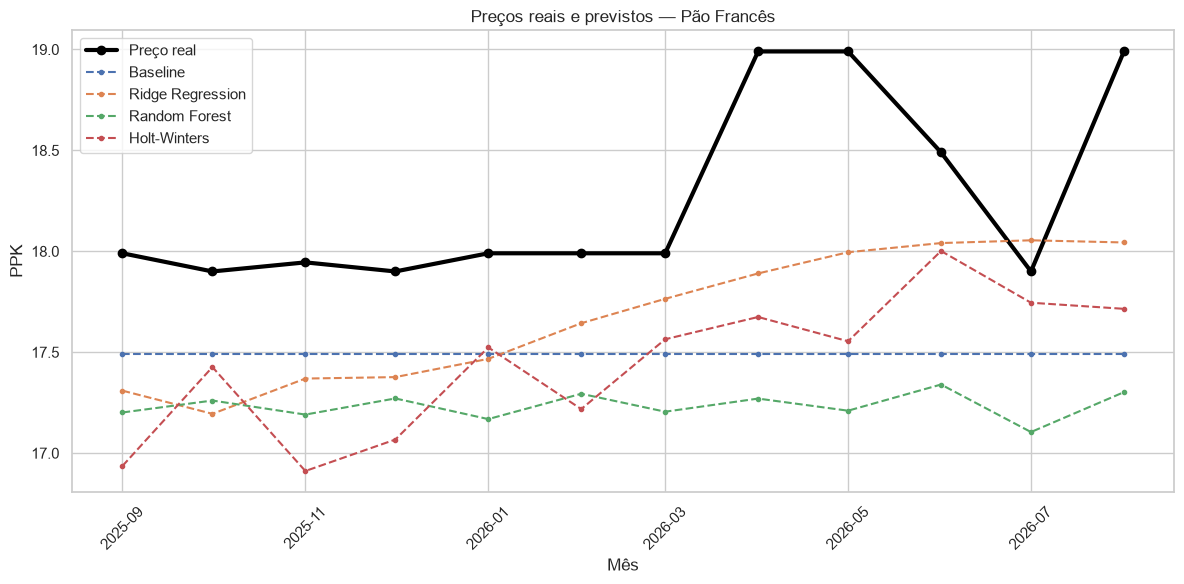

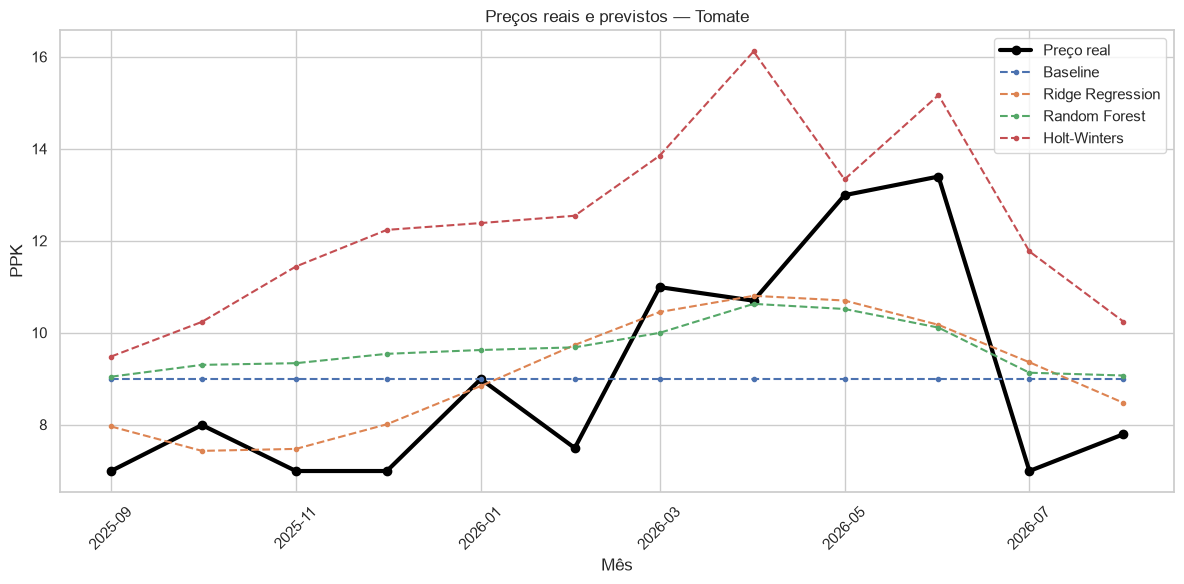

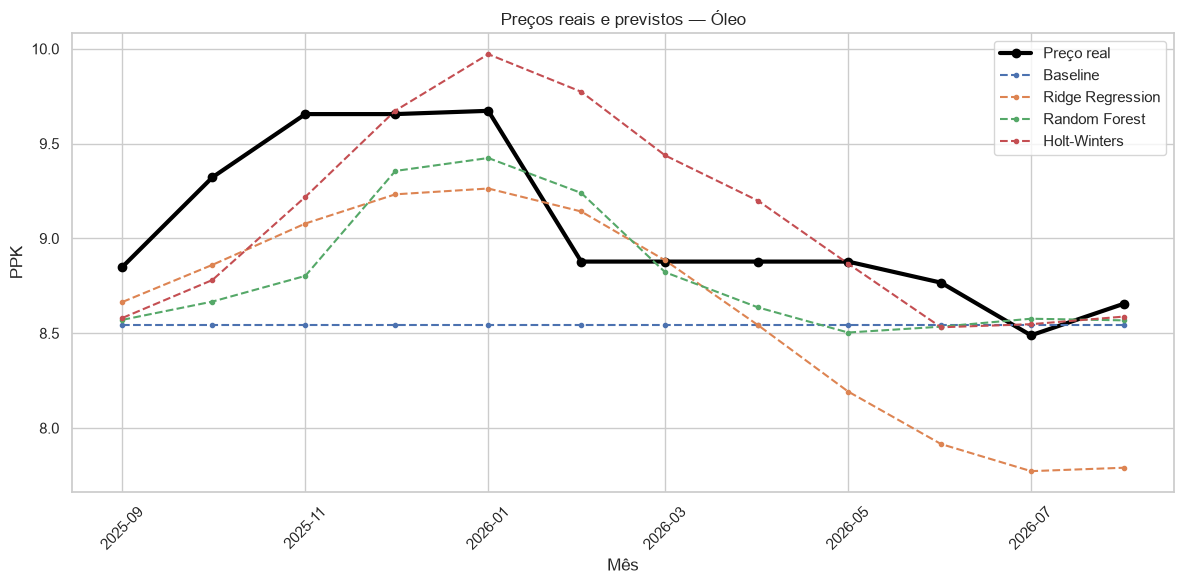

In [13]:
pasta_comparacao = FIGURES / "real_vs_previsto"

pasta_comparacao.mkdir(
    parents=True,
    exist_ok=True
)

for produto, dados in teste_multipassos.groupby("produto"):

    dados = dados.sort_values("mes")

    plt.figure(figsize=(12, 6))

    plt.plot(
        dados["mes"],
        dados["ppk_mediana"],
        label="Preço real",
        color="black",
        linewidth=3,
        marker="o"
    )

    for coluna, modelo in modelos.items():

        plt.plot(
            dados["mes"],
            dados[coluna],
            label=modelo,
            linestyle="--",
            marker="."
        )

    plt.title(f"Preços reais e previstos — {produto}")
    plt.xlabel("Mês")
    plt.ylabel("PPK")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()

    nome_produto = produto.lower().replace(" ", "_")

    plt.savefig(
        pasta_comparacao / f"{nome_produto}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [14]:
resumo = melhores_modelos[
    melhores_modelos["cenario"] == "Múltiplos passos"
].copy()

resumo = resumo[
    ["produto", "modelo", "MAE", "RMSE", "n_observacoes"]
]

display(resumo.round(4))

,produto,modelo,MAE,RMSE,n_observacoes
0,Arroz,Holt-Winters,0.5936,0.6448,12
2,Açúcar,Random Forest,0.2980,0.4127,12
4,Banana Nanica,Baseline,0.3958,0.5851,12
6,Banana Prata,Ridge Regression,0.7295,0.8605,12
8,Batata,Ridge Regression,1.3032,1.5602,12
10,Café,Random Forest,5.1667,6.7615,12
12,Carne Bovina Coxão Mole,Holt-Winters,2.2215,3.2394,12
14,Farinha de Trigo,Ridge Regression,0.1016,0.1190,12
16,Feijão,Ridge Regression,0.8310,1.1735,12
18,Leite,Holt-Winters,0.3492,0.4339,12


## 5. Identificação dos melhores períodos históricos de compra

Nesta etapa, serão identificados os meses historicamente
mais favoráveis para a compra de cada produto.

Serão considerados os preços medianos mensais e os
componentes sazonais identificados na etapa anterior.

O objetivo é identificar períodos recorrentes de preços
mais baixos, reduzindo a influência das tendências de
longo prazo sobre a análise.

In [15]:
perfil_historico = sazonalidade.copy()

perfil_historico = perfil_historico[
    [
        "produto",
        "mes_num",
        "mes",
        "n_anos",
        "mediana_nominal",
        "indice_harmonico",
        "efeito_stl_pct"
    ]
]

display(perfil_historico.round(4))

,produto,mes_num,mes,n_anos,mediana_nominal,indice_harmonico,efeito_stl_pct
0,Arroz,1,Jan,4,5.7980,101.4991,1.9562
1,Arroz,2,Fev,4,5.9400,101.6825,3.1820
2,Arroz,3,Mar,4,5.8295,101.4118,0.1426
3,Arroz,4,Abr,4,5.7030,100.7627,-0.1050
4,Arroz,5,Mai,4,5.6735,99.9140,0.5762
...,...,...,...,...,...,...,...
163,Óleo,8,Ago,4,7.8778,94.5223,-4.8011
164,Óleo,9,Set,4,8.1417,97.8593,-3.4646
165,Óleo,10,Out,4,8.4889,101.9033,-0.6988
166,Óleo,11,Nov,4,8.9556,105.5797,2.0000


In [16]:
periodos_historicos = []

for produto, dados in perfil_historico.groupby("produto"):

    dados = dados.dropna(subset=["indice_harmonico"])

    if dados.empty:
        continue

    melhor = dados.loc[
        dados["indice_harmonico"].idxmin()
    ]

    pior = dados.loc[
        dados["indice_harmonico"].idxmax()
    ]

    periodos_historicos.append({
        "produto": produto,
        "melhor_mes": melhor["mes"],
        "indice_melhor_mes": melhor["indice_harmonico"],
        "pior_mes": pior["mes"],
        "indice_pior_mes": pior["indice_harmonico"],
        "n_anos_melhor_mes": melhor["n_anos"],
        "n_anos_pior_mes": pior["n_anos"],
        "diferenca_pct": (
            1 - melhor["indice_harmonico"] /
            pior["indice_harmonico"]
        ) * 100
    })

periodos_historicos = pd.DataFrame(periodos_historicos).merge(
    testes_sazonais, on="produto", how="left", validate="one_to_one"
)

display(periodos_historicos.round(2))

,produto,melhor_mes,indice_melhor_mes,pior_mes,indice_pior_mes,n_anos_melhor_mes,n_anos_pior_mes,diferenca_pct,q_bh,evidencia_principal
0,Arroz,Ago,98.35,Fev,101.68,4,4,3.28,0.98,False
1,Açúcar,Mai,99.20,Nov,100.81,4,4,1.60,0.98,False
2,Banana Nanica,Mai,92.49,Nov,108.12,4,4,14.46,0.07,False
3,Banana Prata,Ago,95.87,Fev,104.30,4,4,8.08,0.32,False
4,Batata,Nov,86.95,Mai,115.01,4,4,24.40,0.35,False
5,Café,Jul,97.48,Jan,102.59,4,4,4.98,0.98,False
6,Carne Bovina Coxão Mole,Jul,98.28,Jan,101.75,4,4,3.40,0.98,False
7,Farinha de Trigo,Mai,98.27,Nov,101.76,4,4,3.43,0.09,False
8,Feijão,Nov,92.18,Mai,108.48,4,4,15.03,0.05,False
9,Leite,Jan,92.52,Jul,108.09,4,4,14.41,0.02,True


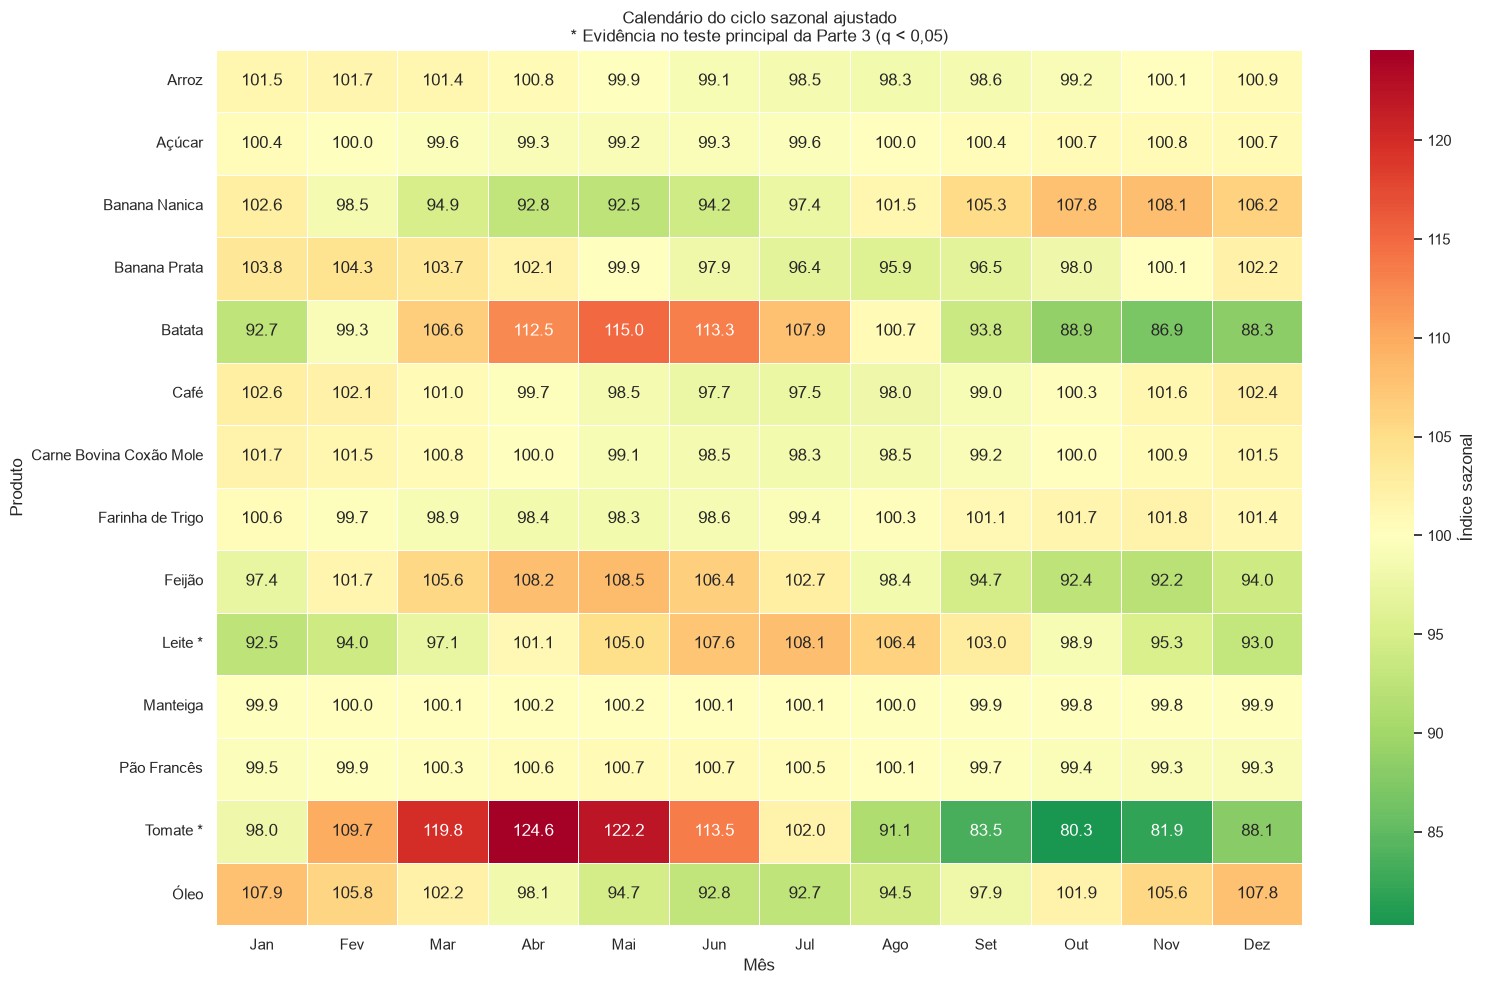

In [17]:
calendario = perfil_historico.pivot(
    index="produto",
    columns="mes_num",
    values="indice_harmonico"
)

calendario = calendario.reindex(
    columns=range(1, 13)
)

calendario.columns = [
    "Jan", "Fev", "Mar", "Abr",
    "Mai", "Jun", "Jul", "Ago",
    "Set", "Out", "Nov", "Dez"
]

produtos_com_evidencia = set(
    testes_sazonais.loc[testes_sazonais["evidencia_principal"], "produto"]
)
calendario.index = [
    f"{produto} *" if produto in produtos_com_evidencia else produto
    for produto in calendario.index
]

plt.figure(figsize=(16, 10))

sns.heatmap(
    calendario,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    center=100,
    linewidths=0.5,
    cbar_kws={"label": "Índice sazonal"}
)

plt.title("Calendário do ciclo sazonal ajustado\n* Evidência no teste principal da Parte 3 (q < 0,05)")
plt.xlabel("Mês")
plt.ylabel("Produto")
plt.tight_layout()

plt.savefig(
    FIGURES / "calendario_historico_compras.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

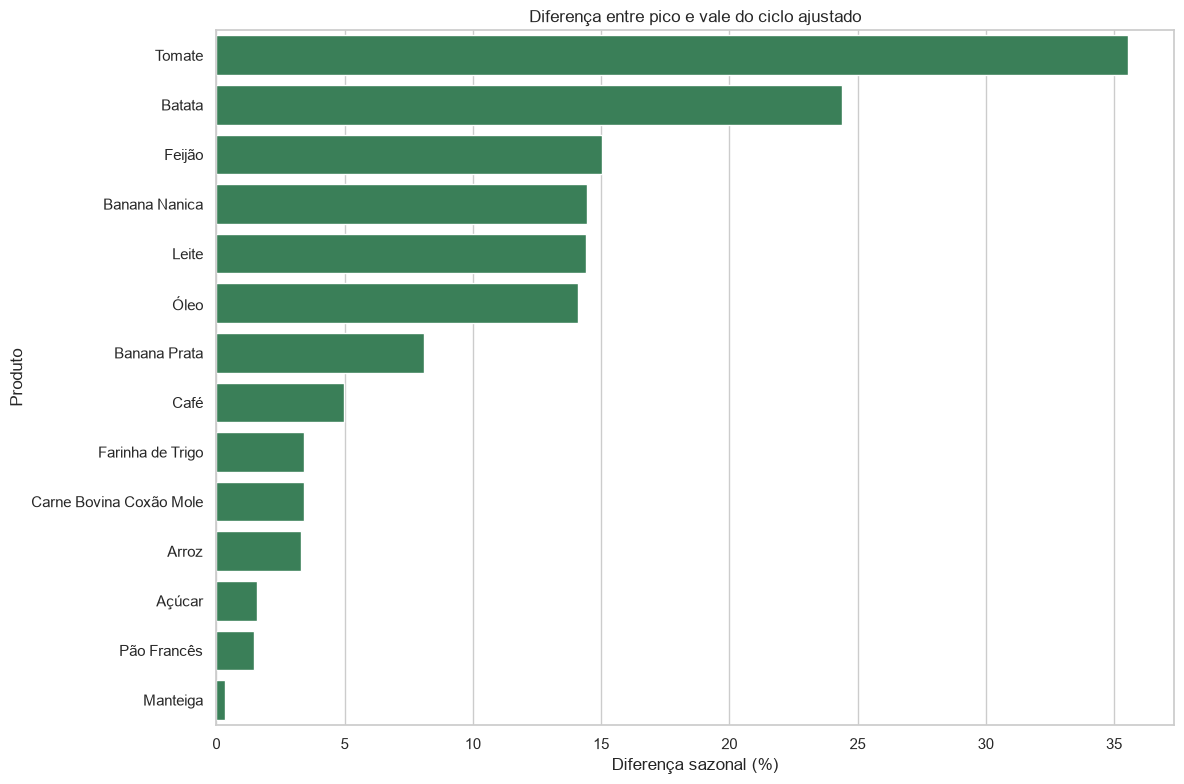

In [18]:
dados_grafico = periodos_historicos.sort_values(
    "diferenca_pct",
    ascending=False
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=dados_grafico,
    x="diferenca_pct",
    y="produto",
    color="seagreen"
)

plt.title("Diferença entre pico e vale do ciclo ajustado")
plt.xlabel("Diferença sazonal (%)")
plt.ylabel("Produto")
plt.tight_layout()

plt.savefig(
    FIGURES / "diferenca_sazonal_produtos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
periodos_historicos.to_csv(
    DATA / "melhores_periodos_historicos.csv",
    index=False
)

print("Análise histórica concluída!")
print(
    f"Produtos analisados: "
    f"{len(periodos_historicos)}"
)

Análise histórica concluída!
Produtos analisados: 14


## 6. Identificação dos melhores períodos futuros de compra

Nesta etapa, serão utilizadas as previsões de preços
geradas pelos modelos de aprendizado de máquina e
de séries temporais.

A seleção dos modelos será baseada no desempenho
observado no cenário de múltiplos passos.

O objetivo é identificar os meses com menores preços
previstos para cada produto e comparar esses resultados
com os padrões históricos de sazonalidade.

In [20]:
candidatos = comparacao[
    (comparacao["cenario"] == "Múltiplos passos") &
    (comparacao["modelo"] != "Baseline")
].copy()

modelos_futuros = (
    candidatos
    .sort_values(["produto", "MAE", "RMSE"])
    .groupby("produto")
    .head(1)
    .reset_index(drop=True)
)

display(
    modelos_futuros[
        [
            "produto",
            "modelo",
            "MAE",
            "RMSE",
            "melhoria_MAE_pct",
            "superou_baseline"
        ]
    ].round(4)
)

,produto,modelo,MAE,RMSE,melhoria_MAE_pct,superou_baseline
0,Arroz,Holt-Winters,0.5936,0.6448,4.5926,True
1,Açúcar,Random Forest,0.2980,0.4127,8.2937,True
2,Banana Nanica,Random Forest,0.4364,0.5963,-10.2410,False
3,Banana Prata,Ridge Regression,0.7295,0.8605,14.6345,True
4,Batata,Ridge Regression,1.3032,1.5602,34.3196,True
5,Café,Random Forest,5.1667,6.7615,29.5686,True
6,Carne Bovina Coxão Mole,Holt-Winters,2.2215,3.2394,27.4004,True
7,Farinha de Trigo,Ridge Regression,0.1016,0.1190,36.1484,True
8,Feijão,Ridge Regression,0.8310,1.1735,37.9859,True
9,Leite,Holt-Winters,0.3492,0.4339,35.4274,True


In [21]:
colunas_modelos = {
    "Ridge Regression": "pred_ridge",
    "Random Forest": "pred_rf",
    "Holt-Winters": "pred_hw"
}

resultados_futuros = []

for _, linha in modelos_futuros.iterrows():

    produto = linha["produto"]
    modelo = linha["modelo"]

    coluna = colunas_modelos[modelo]

    dados = previsoes_futuras[
        previsoes_futuras["produto"] == produto
    ].copy()

    dados = dados.dropna(subset=[coluna])

    dados["preco_previsto"] = dados[coluna]
    dados["modelo_selecionado"] = modelo
    dados["MAE"] = linha["MAE"]
    dados["RMSE"] = linha["RMSE"]
    dados["superou_baseline"] = linha["superou_baseline"]

    resultados_futuros.append(
        dados[
            [
                "mes",
                "produto",
                "preco_previsto",
                "modelo_selecionado",
                "MAE",
                "RMSE",
                "superou_baseline"
            ]
        ]
    )

previsoes_selecionadas = pd.concat(
    resultados_futuros,
    ignore_index=True
)

display(previsoes_selecionadas.round(4))

/var/folders/lr/4_lwmgk57c95kb63vjbrzr2r0000gn/T/ipykernel_88735/1492854363.py:47: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(previsoes_selecionadas.round(4))


,mes,produto,preco_previsto,modelo_selecionado,MAE,RMSE,superou_baseline
0,2026-09-01,Arroz,5.1420,Holt-Winters,0.5936,0.6448,True
1,2026-10-01,Arroz,5.0888,Holt-Winters,0.5936,0.6448,True
2,2026-11-01,Arroz,5.3154,Holt-Winters,0.5936,0.6448,True
3,2026-12-01,Arroz,5.3161,Holt-Winters,0.5936,0.6448,True
4,2027-01-01,Arroz,5.4552,Holt-Winters,0.5936,0.6448,True
...,...,...,...,...,...,...,...
79,2026-10-01,Óleo,9.1116,Holt-Winters,0.3094,0.4008,True
80,2026-11-01,Óleo,9.5259,Holt-Winters,0.3094,0.4008,True
81,2026-12-01,Óleo,9.8464,Holt-Winters,0.3094,0.4008,True
82,2027-01-01,Óleo,10.0628,Holt-Winters,0.3094,0.4008,True


In [22]:
periodos_futuros = []

for produto, dados in previsoes_selecionadas.groupby("produto"):

    dados = dados.sort_values("mes")

    melhor = dados.loc[
        dados["preco_previsto"].idxmin()
    ]

    pior = dados.loc[
        dados["preco_previsto"].idxmax()
    ]

    diferenca = (
        1 - melhor["preco_previsto"] /
        pior["preco_previsto"]
    ) * 100 if pior["preco_previsto"] > 0 else np.nan

    periodos_futuros.append({
        "produto": produto,
        "modelo": melhor["modelo_selecionado"],
        "melhor_mes_futuro": melhor["mes"],
        "menor_preco_previsto": melhor["preco_previsto"],
        "pior_mes_futuro": pior["mes"],
        "maior_preco_previsto": pior["preco_previsto"],
        "diferenca_prevista_pct": diferenca,
        "MAE": melhor["MAE"],
        "RMSE": melhor["RMSE"],
        "superou_baseline": melhor["superou_baseline"]
    })

periodos_futuros = pd.DataFrame(periodos_futuros)

display(periodos_futuros.round(4))

/var/folders/lr/4_lwmgk57c95kb63vjbrzr2r0000gn/T/ipykernel_88735/3577723220.py:35: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(periodos_futuros.round(4))


,produto,modelo,melhor_mes_futuro,menor_preco_previsto,pior_mes_futuro,maior_preco_previsto,diferenca_prevista_pct,MAE,RMSE,superou_baseline
0,Arroz,Holt-Winters,2026-10-01,5.0888,2027-02-01,5.5790,8.7866,0.5936,0.6448,True
1,Açúcar,Random Forest,2027-02-01,4.1539,2026-11-01,4.3526,4.5650,0.2980,0.4127,True
2,Banana Nanica,Random Forest,2027-02-01,6.9319,2027-01-01,7.2531,4.4289,0.4364,0.5963,False
3,Banana Prata,Ridge Regression,2026-10-01,11.3018,2027-01-01,11.6605,3.0758,0.7295,0.8605,True
4,Batata,Ridge Regression,2026-11-01,5.4922,2027-02-01,6.2941,12.7404,1.3032,1.5602,True
5,Café,Random Forest,2027-01-01,59.8325,2027-02-01,61.1858,2.2118,5.1667,6.7615,True
6,Carne Bovina Coxão Mole,Holt-Winters,2026-09-01,53.2362,2027-01-01,57.2106,6.9471,2.2215,3.2394,True
7,Farinha de Trigo,Ridge Regression,2027-02-01,5.3593,2026-11-01,5.4971,2.5079,0.1016,0.1190,True
8,Feijão,Ridge Regression,2026-12-01,8.8056,2026-09-01,9.5798,8.0820,0.8310,1.1735,True
9,Leite,Holt-Winters,2027-01-01,5.2800,2026-09-01,6.0112,12.1651,0.3492,0.4339,True


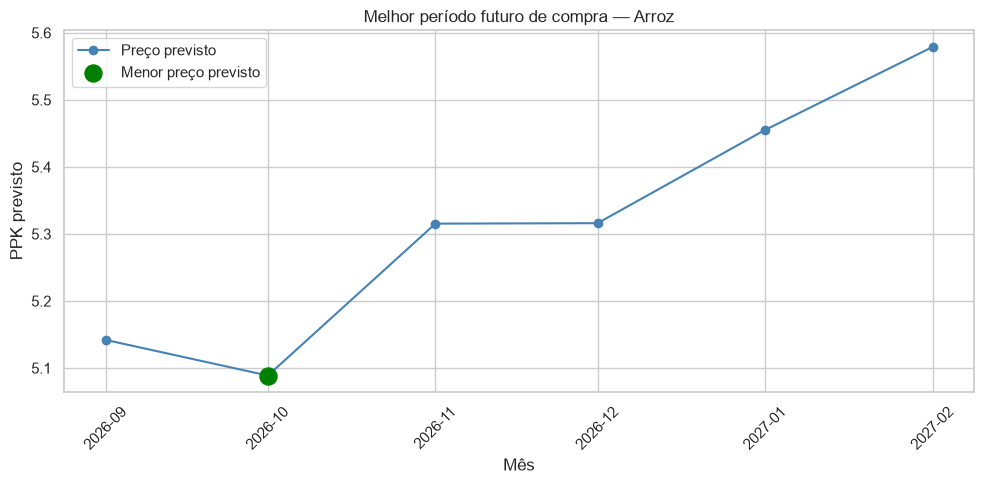

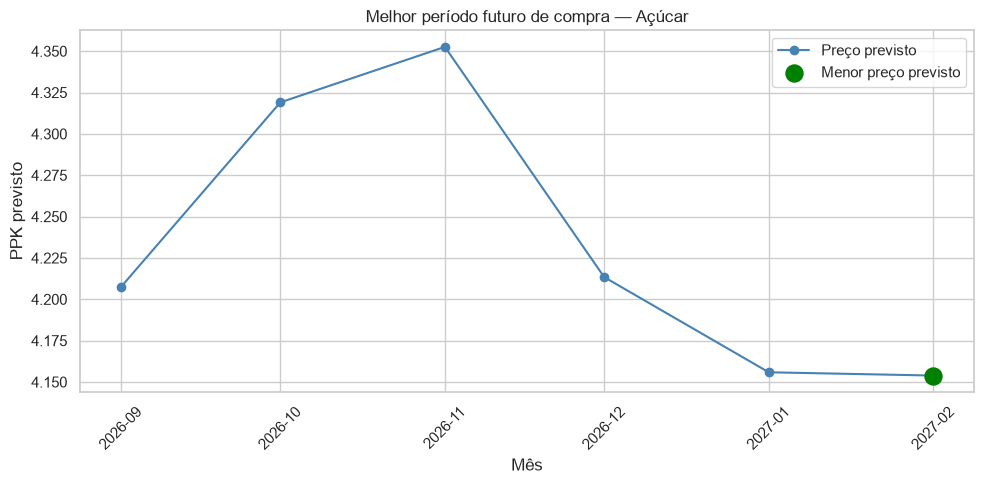

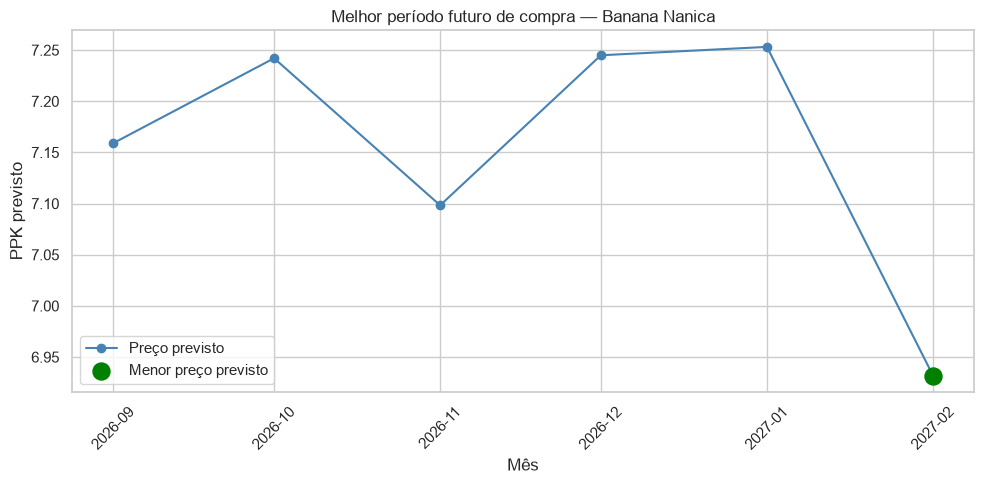

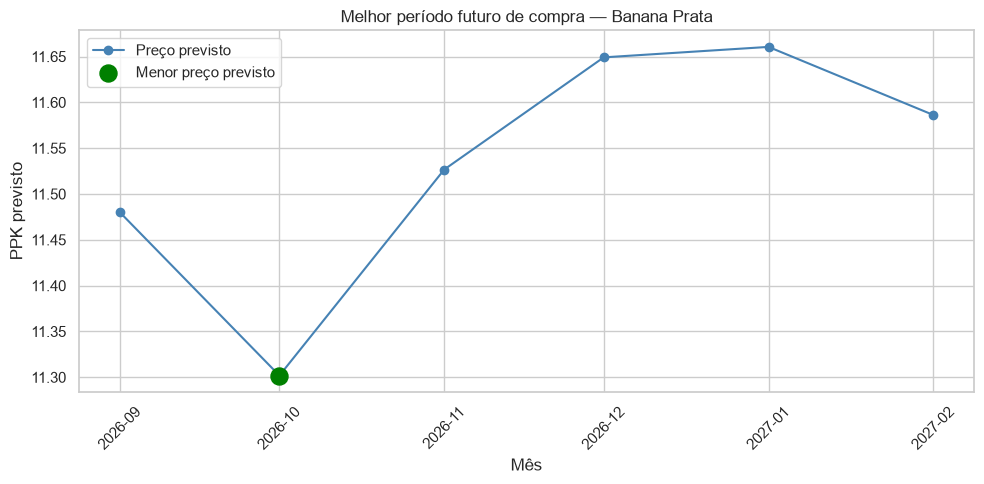

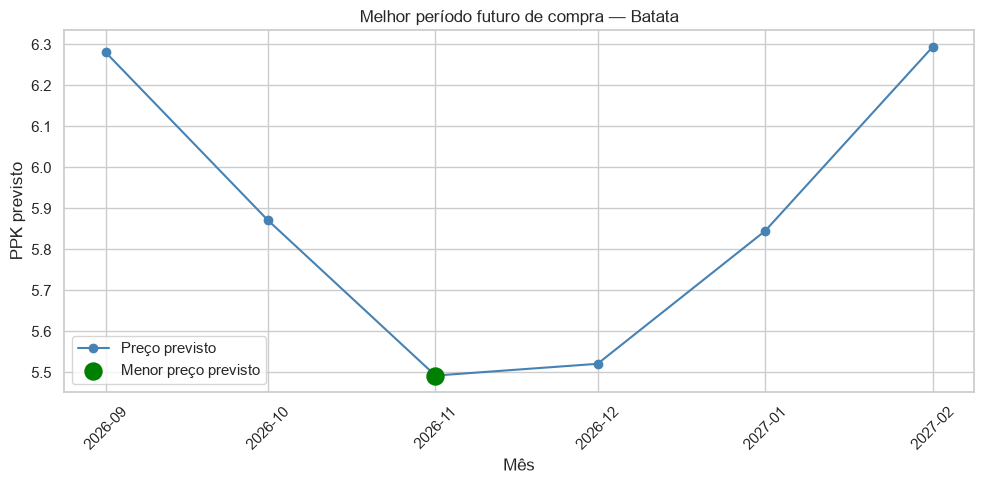

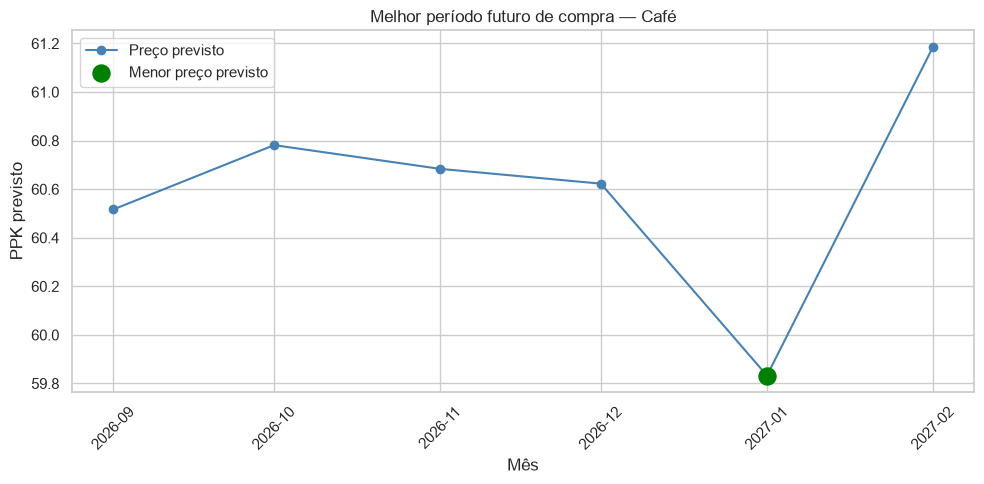

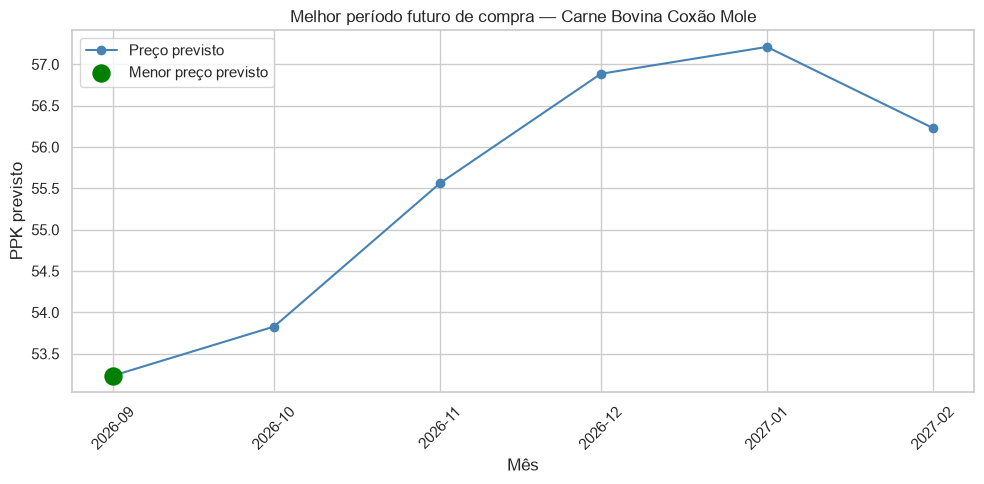

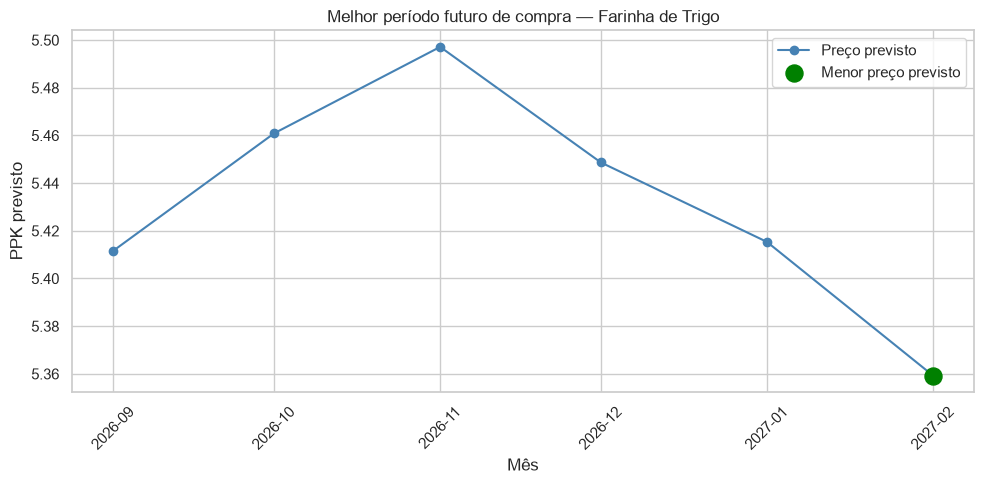

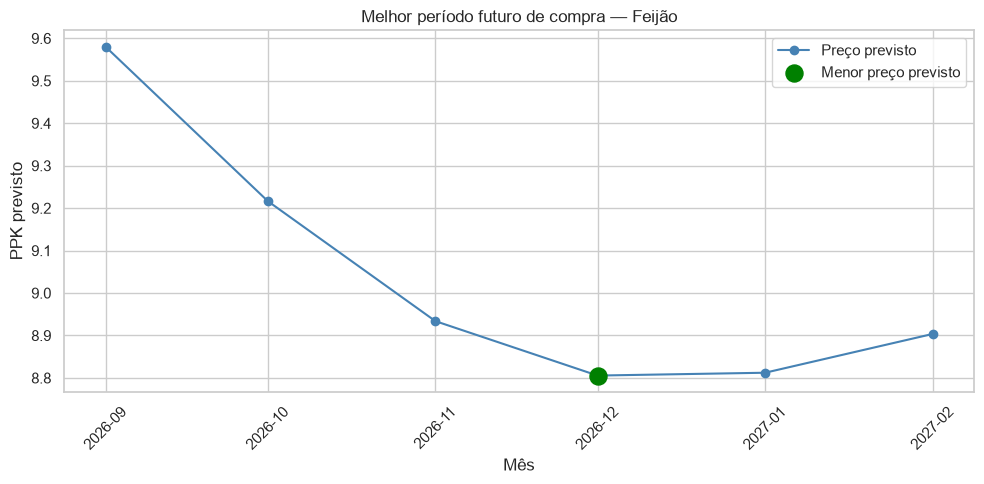

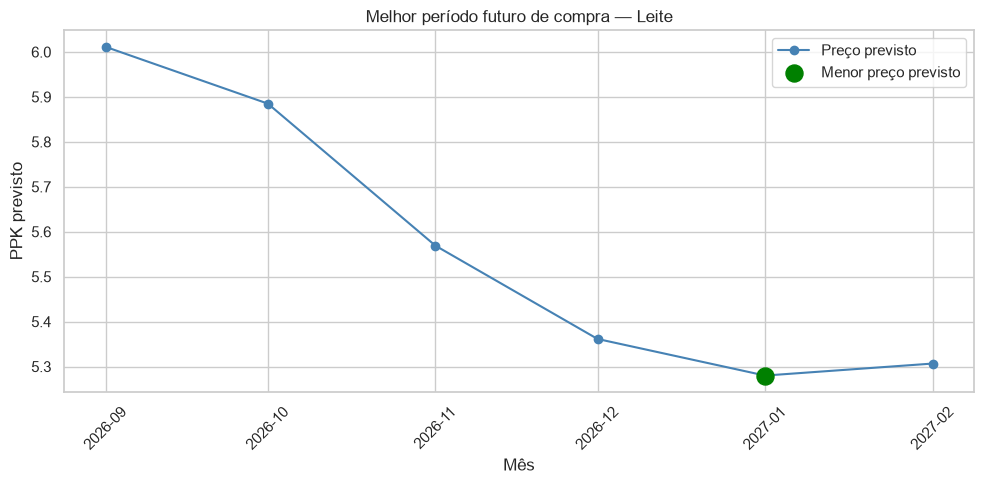

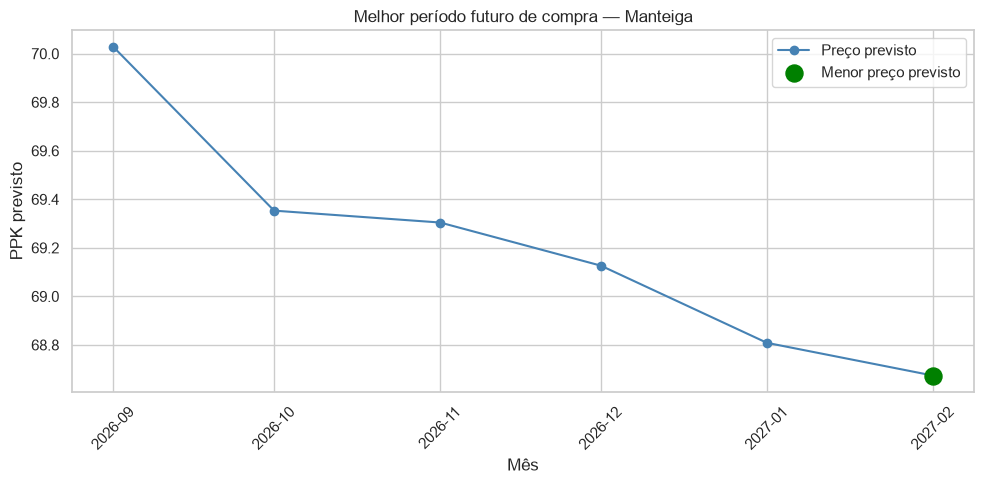

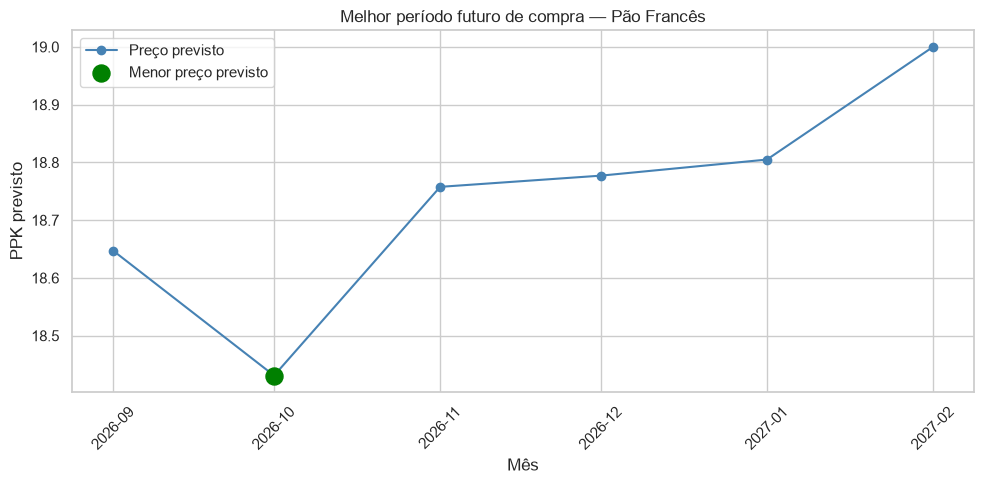

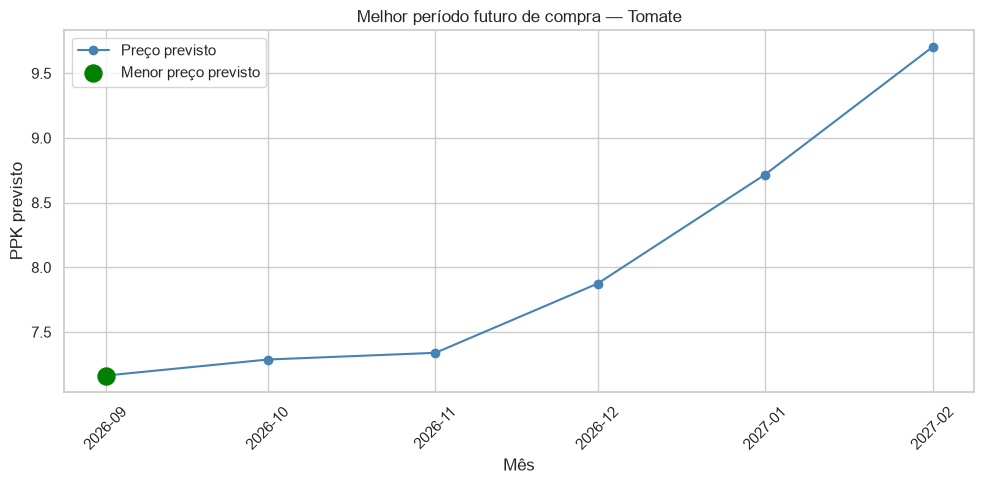

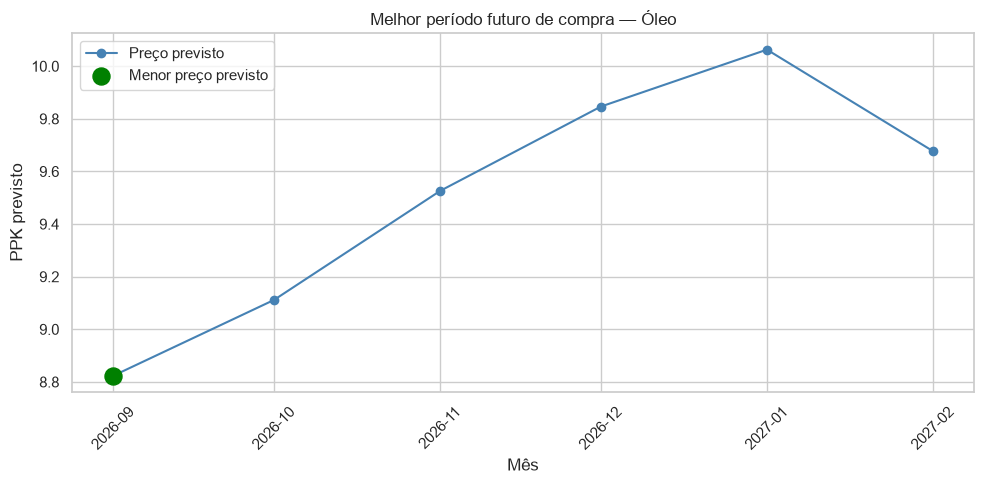

In [23]:
pasta_futuras = FIGURES / "previsoes_futuras"

pasta_futuras.mkdir(
    parents=True,
    exist_ok=True
)

for produto, dados in previsoes_selecionadas.groupby("produto"):

    dados = dados.sort_values("mes")

    melhor = dados.loc[
        dados["preco_previsto"].idxmin()
    ]

    plt.figure(figsize=(10, 5))

    plt.plot(
        dados["mes"],
        dados["preco_previsto"],
        marker="o",
        color="steelblue",
        label="Preço previsto"
    )

    plt.scatter(
        melhor["mes"],
        melhor["preco_previsto"],
        color="green",
        s=150,
        zorder=5,
        label="Menor preço previsto"
    )

    plt.title(f"Melhor período futuro de compra — {produto}")
    plt.xlabel("Mês")
    plt.ylabel("PPK previsto")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()

    nome = produto.lower().replace(" ", "_")

    plt.savefig(
        pasta_futuras / f"{nome}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [24]:
comparacao_periodos = periodos_historicos.merge(
    periodos_futuros,
    on="produto",
    how="outer"
)

meses = {
    1: "Jan", 2: "Fev", 3: "Mar",
    4: "Abr", 5: "Mai", 6: "Jun",
    7: "Jul", 8: "Ago", 9: "Set",
    10: "Out", 11: "Nov", 12: "Dez"
}

comparacao_periodos["mes_futuro_abreviado"] = (
    comparacao_periodos["melhor_mes_futuro"]
    .dt.month
    .map(meses)
)

comparacao_periodos["coincidencia"] = np.where(
    comparacao_periodos["melhor_mes"].notna() &
    comparacao_periodos["melhor_mes_futuro"].notna(),
    np.where(
        comparacao_periodos["melhor_mes"] ==
        comparacao_periodos["mes_futuro_abreviado"],
        "Sim",
        "Não"
    ),
    "Sem dados"
)

display(
    comparacao_periodos[
        [
            "produto",
            "melhor_mes",
            "melhor_mes_futuro",
            "modelo",
            "menor_preco_previsto",
            "coincidencia",
            "superou_baseline"
        ]
    ].round(4)
)

/var/folders/lr/4_lwmgk57c95kb63vjbrzr2r0000gn/T/ipykernel_88735/2087511764.py:43: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,produto,melhor_mes,melhor_mes_futuro,modelo,menor_preco_previsto,coincidencia,superou_baseline
0,Arroz,Ago,2026-10-01,Holt-Winters,5.0888,Não,True
1,Açúcar,Mai,2027-02-01,Random Forest,4.1539,Não,True
2,Banana Nanica,Mai,2027-02-01,Random Forest,6.9319,Não,False
3,Banana Prata,Ago,2026-10-01,Ridge Regression,11.3018,Não,True
4,Batata,Nov,2026-11-01,Ridge Regression,5.4922,Sim,True
5,Café,Jul,2027-01-01,Random Forest,59.8325,Não,True
6,Carne Bovina Coxão Mole,Jul,2026-09-01,Holt-Winters,53.2362,Não,True
7,Farinha de Trigo,Mai,2027-02-01,Ridge Regression,5.3593,Não,True
8,Feijão,Nov,2026-12-01,Ridge Regression,8.8056,Não,True
9,Leite,Jan,2027-01-01,Holt-Winters,5.2800,Sim,True


In [25]:
previsoes_selecionadas.to_csv(
    DATA / "previsoes_selecionadas.csv",
    index=False
)

periodos_futuros.to_csv(
    DATA / "melhores_periodos_futuros.csv",
    index=False
)

comparacao_periodos.to_csv(
    DATA / "melhores_periodos_compra.csv",
    index=False
)

print("Análise dos períodos futuros concluída!")
print("Arquivos salvos com sucesso!")

Análise dos períodos futuros concluída!
Arquivos salvos com sucesso!


## 7. Análise integrada dos resultados

Nesta etapa, serão consolidados os resultados da
avaliação dos modelos, da análise histórica e das
previsões futuras.

Busca-se verificar a capacidade dos modelos de auxiliar
no planejamento de compras, considerando seus erros,
a sazonalidade dos alimentos e as limitações dos dados.

In [26]:
print("=" * 60)
print("RESUMO DA AVALIAÇÃO DOS MODELOS")
print("=" * 60)

print(f"\nProdutos avaliados: {metricas['produto'].nunique()}")
print(f"Modelos avaliados: {metricas['modelo'].nunique()}")
print(f"Total de avaliações: {len(metricas)}")

for cenario in metricas["cenario"].unique():

    dados = melhores_modelos[
        melhores_modelos["cenario"] == cenario
    ]

    print(f"\nCenário: {cenario}")

    print(
        dados["modelo"]
        .value_counts()
        .to_string()
    )

print("\nModelos selecionados para previsões futuras:")

print(
    modelos_futuros["modelo"]
    .value_counts()
    .to_string()
)

print(
    "\nProdutos com modelos que superaram o Baseline:",
    modelos_futuros["superou_baseline"].sum()
)

print(
    "Produtos com modelos que não superaram o Baseline:",
    (~modelos_futuros["superou_baseline"]).sum()
)

RESUMO DA AVALIAÇÃO DOS MODELOS

Produtos avaliados: 14
Modelos avaliados: 4
Total de avaliações: 112

Cenário: Um passo
modelo
Baseline            6
Ridge Regression    5
Holt-Winters        2
Random Forest       1

Cenário: Múltiplos passos
modelo
Ridge Regression    7
Holt-Winters        4
Random Forest       2
Baseline            1

Modelos selecionados para previsões futuras:
modelo
Ridge Regression    7
Holt-Winters        4
Random Forest       3

Produtos com modelos que superaram o Baseline: 13
Produtos com modelos que não superaram o Baseline: 1


In [27]:
analise_final = comparacao_periodos.copy()

analise_final["amplitude_prevista"] = (
    analise_final["maior_preco_previsto"] -
    analise_final["menor_preco_previsto"]
)



analise_final["evidencia"] = analise_final.apply(
    classificar_evidencia,
    axis=1
)

display(
    analise_final[
        [
            "produto",
            "modelo",
            "melhor_mes",
            "melhor_mes_futuro",
            "menor_preco_previsto",
            "amplitude_prevista",
            "MAE",
            "evidencia"
        ]
    ].round(4)
)

/var/folders/lr/4_lwmgk57c95kb63vjbrzr2r0000gn/T/ipykernel_88735/1721840873.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,produto,modelo,melhor_mes,melhor_mes_futuro,menor_preco_previsto,amplitude_prevista,MAE,evidencia
0,Arroz,Holt-Winters,Ago,2026-10-01,5.0888,0.4902,0.5936,Diferença pequena em relação ao erro
1,Açúcar,Random Forest,Mai,2027-02-01,4.1539,0.1987,0.2980,Diferença pequena em relação ao erro
2,Banana Nanica,Random Forest,Mai,2027-02-01,6.9319,0.3212,0.4364,Modelo não superou o Baseline
3,Banana Prata,Ridge Regression,Ago,2026-10-01,11.3018,0.3587,0.7295,Diferença pequena em relação ao erro
4,Batata,Ridge Regression,Nov,2026-11-01,5.4922,0.8019,1.3032,Diferença pequena em relação ao erro
5,Café,Random Forest,Jul,2027-01-01,59.8325,1.3533,5.1667,Diferença pequena em relação ao erro
6,Carne Bovina Coxão Mole,Holt-Winters,Jul,2026-09-01,53.2362,3.9745,2.2215,Indício favorável de compra
7,Farinha de Trigo,Ridge Regression,Mai,2027-02-01,5.3593,0.1379,0.1016,Indício favorável de compra
8,Feijão,Ridge Regression,Nov,2026-12-01,8.8056,0.7742,0.8310,Diferença pequena em relação ao erro
9,Leite,Holt-Winters,Jan,2027-01-01,5.2800,0.7313,0.3492,Indício favorável de compra


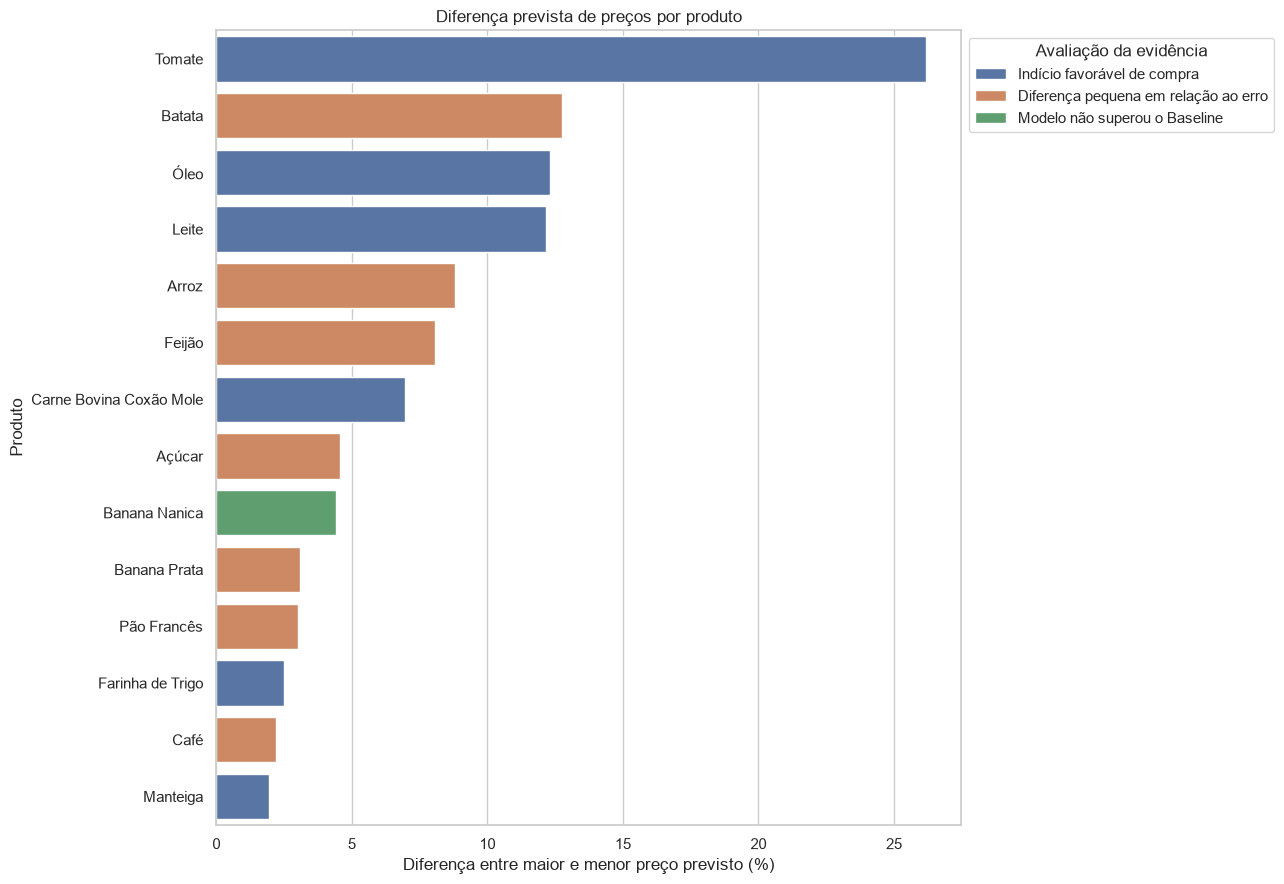

In [28]:
dados_final = analise_final.dropna(
    subset=["diferenca_prevista_pct"]
).sort_values(
    "diferenca_prevista_pct",
    ascending=False
)

plt.figure(figsize=(13, 9))

sns.barplot(
    data=dados_final,
    x="diferenca_prevista_pct",
    y="produto",
    hue="evidencia",
    dodge=False
)

plt.title("Diferença prevista de preços por produto")
plt.xlabel("Diferença entre maior e menor preço previsto (%)")
plt.ylabel("Produto")
plt.legend(
    title="Avaliação da evidência",
    loc="upper left",
    bbox_to_anchor=(1, 1)
)

plt.tight_layout()

plt.savefig(
    FIGURES / "oportunidades_compra.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
tabela_final = analise_final[
    [
        "produto",
        "melhor_mes",
        "melhor_mes_futuro",
        "modelo",
        "menor_preco_previsto",
        "diferenca_prevista_pct",
        "MAE",
        "RMSE",
        "coincidencia",
        "q_bh",
        "evidencia_principal",
        "evidencia"
    ]
].copy()

tabela_final["melhor_mes_futuro"] = (
    tabela_final["melhor_mes_futuro"]
    .dt.strftime("%m/%Y")
)

display(tabela_final.round(2))

tabela_final.to_csv(
    DATA / "resultado_final_compras.csv",
    index=False
)

print("Tabela final exportada com sucesso!")

,produto,melhor_mes,melhor_mes_futuro,modelo,menor_preco_previsto,diferenca_prevista_pct,MAE,RMSE,coincidencia,q_bh,evidencia_principal,evidencia
0,Arroz,Ago,10/2026,Holt-Winters,5.09,8.79,0.59,0.64,Não,0.98,False,Diferença pequena em relação ao erro
1,Açúcar,Mai,02/2027,Random Forest,4.15,4.56,0.30,0.41,Não,0.98,False,Diferença pequena em relação ao erro
2,Banana Nanica,Mai,02/2027,Random Forest,6.93,4.43,0.44,0.60,Não,0.07,False,Modelo não superou o Baseline
3,Banana Prata,Ago,10/2026,Ridge Regression,11.30,3.08,0.73,0.86,Não,0.32,False,Diferença pequena em relação ao erro
4,Batata,Nov,11/2026,Ridge Regression,5.49,12.74,1.30,1.56,Sim,0.35,False,Diferença pequena em relação ao erro
5,Café,Jul,01/2027,Random Forest,59.83,2.21,5.17,6.76,Não,0.98,False,Diferença pequena em relação ao erro
6,Carne Bovina Coxão Mole,Jul,09/2026,Holt-Winters,53.24,6.95,2.22,3.24,Não,0.98,False,Indício favorável de compra
7,Farinha de Trigo,Mai,02/2027,Ridge Regression,5.36,2.51,0.10,0.12,Não,0.09,False,Indício favorável de compra
8,Feijão,Nov,12/2026,Ridge Regression,8.81,8.08,0.83,1.17,Não,0.05,False,Diferença pequena em relação ao erro
9,Leite,Jan,01/2027,Holt-Winters,5.28,12.17,0.35,0.43,Sim,0.02,True,Indício favorável de compra


Tabela final exportada com sucesso!


In [30]:
print("PERÍODOS HISTÓRICOS E FUTUROS")
print("=" * 60)

print("\nCoincidência entre os períodos:")
print(analise_final["coincidencia"].value_counts())

print("\nClassificação das oportunidades:")
print(analise_final["evidencia"].value_counts())

print("\nHorizonte das previsões:")
print(previsoes_futuras["mes"].min().strftime("%m/%Y"))
print(previsoes_futuras["mes"].max().strftime("%m/%Y"))

print("\nProdutos e melhores períodos:")

for _, linha in tabela_final.iterrows():

    print(
        f"\n{linha['produto']}"
        f"\n  Melhor mês histórico: {linha['melhor_mes']}"
        f"\n  Melhor mês previsto: {linha['melhor_mes_futuro']}"
        f"\n  Modelo: {linha['modelo']}"
        f"\n  Evidência: {linha['evidencia']}"
    )

PERÍODOS HISTÓRICOS E FUTUROS

Coincidência entre os períodos:
coincidencia
Não    12
Sim     2
Name: count, dtype: int64

Classificação das oportunidades:
evidencia
Diferença pequena em relação ao erro    7
Indício favorável de compra             6
Modelo não superou o Baseline           1
Name: count, dtype: int64

Horizonte das previsões:
09/2026
02/2027

Produtos e melhores períodos:

Arroz
  Melhor mês histórico: Ago
  Melhor mês previsto: 10/2026
  Modelo: Holt-Winters
  Evidência: Diferença pequena em relação ao erro

Açúcar
  Melhor mês histórico: Mai
  Melhor mês previsto: 02/2027
  Modelo: Random Forest
  Evidência: Diferença pequena em relação ao erro

Banana Nanica
  Melhor mês histórico: Mai
  Melhor mês previsto: 02/2027
  Modelo: Random Forest
  Evidência: Modelo não superou o Baseline

Banana Prata
  Melhor mês histórico: Ago
  Melhor mês previsto: 10/2026
  Modelo: Ridge Regression
  Evidência: Diferença pequena em relação ao erro

Batata
  Melhor mês histórico: Nov
  

In [31]:
print("VALIDAÇÃO DA PARTE 5")
print("=" * 60)

print("\nProdutos no histórico:", historico["produto"].nunique())
print("Produtos avaliados:", metricas["produto"].nunique())
print("Produtos com previsões:", previsoes_selecionadas["produto"].nunique())

print("\nMétricas negativas:")
print((metricas[["MAE", "RMSE"]] < 0).sum())

print("\nCasos em que RMSE é menor que MAE:")
print((metricas["RMSE"] + 1e-10 < metricas["MAE"]).sum())

print("\nPrevisões com preços inválidos:")
print((previsoes_selecionadas["preco_previsto"] <= 0).sum())

print("\nProdutos duplicados na tabela final:")
print(tabela_final["produto"].duplicated().sum())

print("\nValores ausentes na tabela final:")
print(tabela_final.isna().sum())

print("\nRESULTADO FINAL")
print(tabela_final.round(3).to_string(index=False))

VALIDAÇÃO DA PARTE 5

Produtos no histórico: 20
Produtos avaliados: 14
Produtos com previsões: 14

Métricas negativas:
MAE     0
RMSE    0
dtype: int64

Casos em que RMSE é menor que MAE:
0

Previsões com preços inválidos:
0

Produtos duplicados na tabela final:
0

Valores ausentes na tabela final:
produto                   0
melhor_mes                0
melhor_mes_futuro         0
modelo                    0
menor_preco_previsto      0
diferenca_prevista_pct    0
MAE                       0
RMSE                      0
coincidencia              0
q_bh                      0
evidencia_principal       0
evidencia                 0
dtype: int64

RESULTADO FINAL
                produto melhor_mes melhor_mes_futuro           modelo  menor_preco_previsto  diferenca_prevista_pct   MAE  RMSE coincidencia  q_bh  evidencia_principal                            evidencia
                  Arroz        Ago           10/2026     Holt-Winters                 5.089                   8.787 0.594 0.645  

## 8. Períodos ainda futuros na data de consulta

A tabela original preserva todo o horizonte do modelo.
A tabela abaixo considera apenas meses completos
posteriores ao mês da consulta. A amplitude é recalculada nesse recorte e comparada
ao mesmo MAE do teste de múltiplos passos. Com apenas um mês restante, a diferença
entre meses fica sem classificação. A tabela usa as projeções originais.

A data de referência pode ser alterada para
reproduzir a análise.

In [32]:
data_referencia = pd.Timestamp("2026-11-25")
mes_seguinte = data_referencia.to_period("M").to_timestamp() + pd.offsets.MonthBegin(1)
restantes = previsoes_selecionadas.loc[
    (previsoes_selecionadas["mes"] >= mes_seguinte) &
    (previsoes_selecionadas["preco_previsto"] > 0)
].copy()
melhores_restantes = (restantes.sort_values(["produto", "preco_previsto", "mes"])
    .groupby("produto").head(1).reset_index(drop=True))
amplitudes_restantes = (
    restantes.groupby("produto", as_index=False)
    .agg(
        meses_disponiveis=("mes", "nunique"),
        minimo=("preco_previsto", "min"),
        maximo=("preco_previsto", "max")
    )
    .assign(amplitude_prevista=lambda dados: (dados["maximo"] - dados["minimo"]).where(
        dados["meses_disponiveis"] >= 2
    ))
)
melhores_restantes = melhores_restantes.merge(
    amplitudes_restantes[["produto", "meses_disponiveis", "amplitude_prevista"]],
    on="produto", validate="one_to_one"
)
melhores_restantes["evidencia"] = pd.Series(
    [classificar_evidencia(linha) for linha in melhores_restantes.to_dict("records")],
    index=melhores_restantes.index, dtype="str"
)
display(melhores_restantes.round(4))
melhores_restantes.to_csv(DATA / "melhores_periodos_restantes.csv", index=False)


/var/folders/lr/4_lwmgk57c95kb63vjbrzr2r0000gn/T/ipykernel_88735/4199447141.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(melhores_restantes.round(4))


,mes,produto,preco_previsto,modelo_selecionado,MAE,RMSE,superou_baseline,meses_disponiveis,amplitude_prevista,evidencia
0,2026-12-01,Arroz,5.3161,Holt-Winters,0.5936,0.6448,True,3,0.2629,Diferença pequena em relação ao erro
1,2027-02-01,Açúcar,4.1539,Random Forest,0.2980,0.4127,True,3,0.0595,Diferença pequena em relação ao erro
2,2027-02-01,Banana Nanica,6.9319,Random Forest,0.4364,0.5963,False,3,0.3212,Modelo não superou o Baseline
3,2027-02-01,Banana Prata,11.5862,Ridge Regression,0.7295,0.8605,True,3,0.0743,Diferença pequena em relação ao erro
4,2026-12-01,Batata,5.5209,Ridge Regression,1.3032,1.5602,True,3,0.7732,Diferença pequena em relação ao erro
5,2027-01-01,Café,59.8325,Random Forest,5.1667,6.7615,True,3,1.3533,Diferença pequena em relação ao erro
6,2027-02-01,Carne Bovina Coxão Mole,56.2291,Holt-Winters,2.2215,3.2394,True,3,0.9815,Diferença pequena em relação ao erro
7,2027-02-01,Farinha de Trigo,5.3593,Ridge Regression,0.1016,0.1190,True,3,0.0894,Diferença pequena em relação ao erro
8,2026-12-01,Feijão,8.8056,Ridge Regression,0.8310,1.1735,True,3,0.0980,Diferença pequena em relação ao erro
9,2027-01-01,Leite,5.2800,Holt-Winters,0.3492,0.4339,True,3,0.0814,Diferença pequena em relação ao erro


## 9. Conclusão

Na execução original, foram avaliados 14 produtos
e quatro modelos, com 12 observações por produto
em cada cenário.

Ridge Regression venceu em sete produtos no cenário
de múltiplos passos, enquanto o Baseline venceu
em seis no cenário de um passo.

No horizonte original, seis produtos apresentaram
indício favorável pelo critério exploratório,
sete apresentaram amplitude pequena em relação
ao MAE e um não superou o Baseline.

No horizonte original, o vale histórico coincidiu com o menor preço previsto
para batata e leite. A coincidência da batata é descritiva, pois o produto
ficou acima do limiar de significância do teste principal da Parte 3.

No recorte de dezembro de 2026 a fevereiro de 2027, com data de referência
de 25/11/2026, tomate e óleo passam pelo mesmo critério exploratório.
O leite tem seu menor preço previsto em janeiro, com amplitude abaixo do MAE
nesse recorte.

Esses resultados sugerem que a previsão pode
complementar a análise de sazonalidade, mas não
garante economia.

O índice histórico não demonstra, isoladamente,
sazonalidade estatisticamente significativa.

Na limpeza, os limites para excluir preços extremos usam a mediana de toda a série, incluindo o período de teste. Com limites calculados apenas no treino, dois registros de treino, entre os produtos do teste, mudaram de classificação.
O mesmo período de teste foi usado para escolher os modelos e informar seu erro, o que pode produzir estimativas otimistas.
Uma avaliação independente calcularia os limites da limpeza com o treino, escolheria os modelos em um período de validação e mediria o erro em um período posterior reservado.

Os preços são expressos na unidade PPK da base,
cuja padronização deve ser confirmada.

A amplitude comparada ao MAE é uma heurística,
não um intervalo de confiança.

A integração com a análise de acessibilidade deve
considerar o custo da cesta em relação ao salário
mínimo, sem confundir preço unitário com custo total.

A conclusão integrada reúne os resultados de acessibilidade da Parte 2 e a evidência dos testes sazonais da Parte 3.

### Integração com a análise de sazonalidade

A análise de sazonalidade identificou evidência
estatística de um ciclo anual em dois dos 14
produtos elegíveis: tomate e leite.

Para o leite, janeiro foi o vale histórico e o menor preço previsto tanto
no horizonte original quanto nos meses restantes. A amplitude entre os meses
restantes ficou abaixo do MAE do modelo.

Para o tomate, o ciclo histórico indicou outubro,
enquanto a previsão dos meses restantes indicou
dezembro de 2026. No horizonte original, o menor preço previsto foi em setembro de 2026.

Essa diferença demonstra que a sazonalidade e
os modelos de previsão são ferramentas
complementares para o planejamento de compras.

Para os demais produtos, os períodos históricos
identificados devem ser interpretados de maneira
descritiva, pois não apresentaram evidência
estatística suficiente de sazonalidade anual.

As previsões não representam garantia de economia
e devem ser interpretadas considerando os erros
dos modelos e as limitações da base de dados.

## 10. Conclusão integrada das perguntas de pesquisa

O presente estudo analisou a evolução dos preços dos alimentos da cesta básica entre setembro de 2022 e agosto de 2026, considerando três aspectos principais: acessibilidade econômica, sazonalidade dos preços e previsão de períodos de compra.

### 10.1. Acessibilidade da cesta básica

Os resultados indicaram que, apesar do crescimento nominal do custo estimado da cesta básica, houve uma redução do comprometimento do salário mínimo ao longo do período analisado.

No cenário com banana Nanica, o comprometimento salarial passou de 63,57% para 57,62%, enquanto no cenário com banana Prata passou de 63,57% para 58,49%.

Também foi observada uma redução na quantidade estimada de horas de trabalho necessárias para adquirir a cesta.

Esses resultados sugerem uma melhora relativa na acessibilidade econômica da cesta básica em relação ao salário mínimo, considerando as aproximações e limitações adotadas.

### 10.2. Influência da sazonalidade nos preços

A análise de sazonalidade identificou evidências estatísticas de um ciclo anual em dois dos 14 produtos elegíveis: tomate e leite.

O tomate apresentou outubro como o mês de menor preço no ciclo sazonal ajustado, enquanto o leite apresentou janeiro.

Para os demais produtos, não foram encontradas evidências estatísticas suficientes de sazonalidade anual no teste principal. Dessa forma, seus períodos históricos de menor preço devem ser interpretados de maneira descritiva.

### 10.3. Previsão dos melhores períodos de compra

A avaliação dos modelos demonstrou que o Ridge Regression apresentou o menor MAE em sete dos 14 produtos no cenário de múltiplos passos, seguido pelo Holt-Winters, com quatro produtos, Random Forest, com dois, e Baseline, com um.

No cenário de um passo, o Baseline apresentou o melhor desempenho em seis produtos, demonstrando que modelos mais complexos nem sempre produzem melhores resultados.

Considerando o horizonte original das previsões, seis produtos apresentaram indícios favoráveis de oportunidades de compra pelo critério exploratório adotado.

Nos meses completos restantes na consulta de 25/11/2026, de dezembro de 2026 a fevereiro de 2027,
tomate e óleo atenderam ao critério exploratório. Para o leite, janeiro coincide com o vale
histórico, com amplitude prevista abaixo do MAE nesse recorte.

### 10.4. Considerações finais

A integração dos resultados demonstra que a análise da acessibilidade econômica, da sazonalidade e dos modelos de previsão pode contribuir para um planejamento de compras mais informado.

Enquanto a análise de acessibilidade permite compreender o impacto dos preços sobre o poder de compra, a sazonalidade auxilia na identificação de padrões históricos, e os modelos de previsão permitem estimar possíveis comportamentos futuros dos preços.

Entretanto, as previsões não representam garantia de economia. Os resultados estão sujeitos aos erros dos modelos, à quantidade de observações disponíveis, às aproximações das unidades de medida e às condições econômicas que podem influenciar os preços.

A seleção dos modelos utilizando os resultados do conjunto de teste também constitui uma limitação metodológica, sendo recomendada uma validação temporal independente em trabalhos futuros.

Conclui-se que a utilização conjunta dessas técnicas pode auxiliar na compreensão do comportamento dos preços dos alimentos e na tomada de decisões, desde que sejam consideradas as limitações e incertezas das análises realizadas.